# E88 · Every photon: a neural localiser tried on a full dSTORM movie, and how it failed

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: two full dSTORM recordings of Unc-13 at *Drosophila* neuromuscular junctions (Mrestani 2022, Zenodo 7328805, CC BY 4.0), 15,000 frames each, reduced to a 1.7 MB summary and small JSON tables from a stored run |
| **Time** | About 1 minute on 2 cores. The notebook replays a stored run; the heavy run is not repeated |
| **You will learn** | **How many frames** a super-resolution movie needs, by a **stability rule** and a **block bootstrap** · **DECODE-style networks** trained on simulators · the **paired-frame test** of error bars without ground truth · why a **simulation pass** says nothing about a microscope · the **companion halo** and a **population replicate with a lineup** · a **calibration certificate** for a trained network · **auditing a Laplace fitter with NUTS**, and a start-value trap in nutpie's `with_data` · how **cross-correlation drift correction** breaks · why a **random split flatters FRC** |

> **Do not rerun the heavy parts on limited hardware.** Every network number here comes from one stored
> run that read 2.4 GB of raw movies and took hours on a 16-core desktop with a 24 GB GPU and 64 GB of
> memory. A normal run loads small JSON files from `results/E88/` and a 1.7 MB summary, needs no GPU and
> no download, and refuses any other run level. The heavy run is in `tools/run_e88_classical.py`,
> `tools/run_e88_net.py` and `tools/run_e88_full.py`.

## The setting

E58 showed that super-resolution microscopy is a statistics problem. In dSTORM (Heilemann et al. 2008)
almost every dye molecule is dark at any moment and a sparse random few blink on, so each camera frame
holds a handful of isolated spots whose centres can be found to a few nanometres, far below the 250 nm
blur of the optics. E58 worked on 2,000 frames of a small crop. This notebook takes the full recording the
crop came from and a second one, 15,000 frames each, from the study of the synaptic protein Unc-13 by
Dannhäuser et al. (2022).

Suppose the lead of an imaging core is planning a repeat of that experiment. On the camera a field takes
only three minutes, but at 45 junctions per channel that is 2.2 hours of scope time and 54 GB of data per
channel, and the dye bleaches all the while. The lead asks three questions. For these two recordings, how many
frames would have given the same answer? How far apart are the two recordings? And the lead keeps being told to
replace the core's fitter with a neural network: would that change the answer, and what would they have to check
before trusting one?

The third question is the hard one. Networks such as DECODE (Speiser et al. 2021) are trained entirely on
simulated frames, and on simulation they beat classical fitters, above all when spots overlap. On a real
movie nothing is known, and a network still prints a confident position and error bar for every blink. So
much of this notebook is about checks that need **no ground truth**: two frames of the same molecule, the
ring of faint detections around bright ones, a simulated replicate of the whole population, and a
certificate that says where the network was never tested. We turn the same checks on the classical fitter,
because a network can only be judged against a baseline whose own error bars have been checked.

The network failed. The most useful thing this notebook can do is show how it failed, and how you would
have caught it before trusting it. Each check has a threshold set before we looked at the result, and
where a check came later we say so where it is used.

**What "the same answer" means.** N is the smallest frame count at which three things hold, in both
recordings, inside the authors' masks of the terminal boutons, at N and at every larger N on the grid. The
resolution by Fourier ring correlation (FRC) is within 10% of its 15,000-frame value. So is the number of
clusters. And a time-block bootstrap band at N overlaps the band at 15,000. "Frames" means the
first N frames of a full movie, which stands in for a shorter acquisition but keeps the full movie's
bleaching history. The cluster count is our own readout (connected components on a 10 nm render), not the
paper's HDBSCAN subclusters: a tool for this decision, not a biological measurement.

**The methods.** The classical baseline is E58's pipeline: detection, a Laplace fit of each blob with the
number of emitters $K$ chosen by evidence, and a 201-frame rolling background. The network is a
DECODE-style U-Net written from the paper in plain JAX. It reads 3 frames and predicts, at every pixel, a
detection probability, a sub-pixel position, photons and an sd for each; those sds are per-pixel
marginals, not a joint posterior over sets of emitters. **Network A** is trained for 40,000 steps on E58's
forward model (Gaussian PSF, flat background, independent frames), a naive simulator on purpose. **Network
B** starts from A and trains 12,000 more steps on a simulator built from recording 7, with a stacked PSF,
real background maps and blinks that persist. Recording 32 plays no part in training, so it is where the
networks are judged.

## The plan

| Part | Question | Tool |
|---|---|---|
| 1 | What does a full recording look like, and what does it cost? | raw frames, renders, bleaching |
| 2 | Does the camera calibration hold along a movie? | block photon-transfer fits |
| 3 | How many frames does the classical pipeline need? | the decision rule, a block bootstrap |
| 4 | Do spots overlap enough for a network to help? | neighbour statistics |
| 5 | What did the network cost to build and use? | timings |
| 6 | Does it pass on simulation, and what is that worth? | recall, CRLB, a coverage grid |
| 7 | Are its error bars and detections honest on real frames? | paired frames, halo, replicate, NUTS |
| 8 | Why did the NUTS audit of the fitter fail? | PyMC and nutpie, live |
| 9 | All the checks together | a table of thresholds |
| 10 | Why does drift correction break on network output? | cross-correlation |
| 11 | How much does a random split flatter FRC? | random and block splits |
| 12 | Does the network change the number of frames? | the decision rule on network rows |
| 13 | What to tell the core | a calibration certificate |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import sys
import time

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import HTML, Markdown, display
from matplotlib import animation
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import NullFormatter
from scipy import ndimage as ndi
from scipy import stats

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, Store, banner, estimated, git_hash, measured

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests `sys.modules.get("jax")`, which
# would import all of JAX for nothing. Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 88
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "replay"
if LEVEL != "replay":
    raise PreflightError(f"PYMC_CHALLENGES_RUN={LEVEL!r}: E88 has one level, replay. The heavy run is not a notebook "
                         "cell: it is tools/run_e88_full.py, and it is not for limited hardware.")

CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
PIXEL_NM, CYCLE_MS, FRAMES, SIDE, PATCH = 127.0, 11.742, 15000, 200, 11
RECS = {"r7": "recording 7", "r32": "recording 32"}
GRID = (2000, 3000, 4000, 5000, 6000, 7500, 9000, 10500, 12000, 13500, 15000)
CLASSICAL, NET_A, NET_B, SINGLE, MUTED, LINE_COL = "#0b6e8a", "#b2182b", "#d98200", "#5f6b73", "#9a9a9a", "#111111"
COLOUR = {"chosen": CLASSICAL, "K1": SINGLE, "a": NET_A, "b": NET_B}
NAME = {"chosen": "classical, chosen K", "K1": "classical, K = 1", "a": "network A", "b": "network B"}
DARK = plt.get_cmap("inferno").with_extremes(bad="black")



def markdown_table(frame):
    """A DataFrame as a Markdown table: pandas needs `tabulate` for this, and it is not a dependency here."""
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * frame.shape[1]]
    lines += ["| " + " | ".join(str(cell).replace("|", "/") for cell in row) + " |" for row in frame.to_numpy()]
    return Markdown("\n".join(lines))


store = Store("E88")
data.describe("dannhauser2022_e88_summary")
pack = np.load(data.path("dannhauser2022_e88_summary"), allow_pickle=False)
print(f"\nNotice carried in the file: {pack['attribution']}\n")
summary = store.load_json("summary")
certificate = store.load_json("certificate")
paired = store.load_json("paired_report")
halo = store.load_json("halo_report")
replicate = store.load_json("replicate_report")
audit = store.load_json("audit_nuts_report")
overlap_posthoc = store.load_json("p2b_overlap_posthoc")
posthoc = {name: store.load_json(f"posthoc_{name}") for name in ("sim", "real", "halo", "psf", "frames", "stuck", "nuts_cold", "nuts_warm")}
decisions = {"classical": store.load_json("p2b_decision"), "classical_line": store.load_json("p2b_decision_line")}
for net in ("a", "b"):
    for tail in ("", "_line", "_cdrift", "_line_cdrift"):
        decisions[net + tail] = store.load_json(f"decision_{net}{tail}")
started = time.perf_counter()
print(f"{CORES} cores here. Level: {LEVEL}. Written outcome of the stored run: {summary['outcome']}.")

dannhauser2022_e88_summary: NumPy archive, not a table: open data.path() with np.load. What E88 draws, for recordings r7 and r32 (dStorm647_Unc13_7 and _32): the authors' masks (<rec>_mask), two raw frames (<rec>_frames, at show_frames), background per 100 frames, blobs and rows per 500-frame block, full-field renders on a 0.25 px grid (<rec>_render_chosen, _a, _b), stored drift (<rec>_drift*, px per 1,000-frame block), paired-test z quantiles (<rec>_z_*, sim_z_*, at z_quantiles), FRC curves (<rec>_frc_*: period in nm, FRC). Recording 7 only: a 3 um zoom at 10 nm (zoom_*), the block and rest renders of one drift block (drift_demo_*), per-spot audit results (audit_*), four spots' pixels (spot_*) and a 40 px window for an animation (animation_*). lineup_*: the check-3 lineups. psf_band: bootstrap band of the stacked PSF. `attribution` holds the notice.
  source: Mrestani (2022), Example raw dSTORM data of Brp (Alexa Fluor532) and Unc-13 (Alexa Fluor647), Zenodo doi:10.5281/zenodo.7328805

In [2]:
display(Markdown(banner(
    level="replay",
    wall_time=measured("0.6-1.1", "min for this replay on 2 cores, warm and empty compile cache, builds of 2026-11-02"),
    peak_ram=measured("0.8-1.1", "GB, whole process tree, this replay, across builds"),
    peak_vram=measured(0, "GB in this run: every GPU number is stored"),
    disk=measured(1.7, "MB in data/, and about 0.5 MB of JSON in results/E88/"),
    download=measured(0, "MB for a reader. The stored run read 2.4 GB of TIFFs"),
    precision=measured("float32 in the stored networks, float64 here", ""),
    chains=measured(4, "chains on each of 4 live spots; 200 spots stored"),
    hardware=measured("Ryzen 5950X on 2 cores; stored GPU tables from an RTX 3090 Ti", ""),
    build_date=measured("2026-11-02", ""),
    git_hash=measured(git_hash() or "unknown", ""),
    smaller_machine=estimated("this replay is the small problem: no reader needs more", ""))))

Loaded from the stored full run: these numbers are not from this machine.

| | Value | Status |
|---|---|---|
| Wall time | 0.6-1.1 min for this replay on 2 cores, warm and empty compile cache, builds of 2026-11-02 | measured |
| Peak RAM | 0.8-1.1 GB, whole process tree, this replay, across builds | measured |
| Peak VRAM | 0 GB in this run: every GPU number is stored | measured |
| Disk | 1.7 MB in data/, and about 0.5 MB of JSON in results/E88/ | measured |
| Download size | 0 MB for a reader. The stored run read 2.4 GB of TIFFs | measured |
| Precision | float32 in the stored networks, float64 here | measured |
| Chains | 4 chains on each of 4 live spots; 200 spots stored | measured |
| Hardware | Ryzen 5950X on 2 cores; stored GPU tables from an RTX 3090 Ti | measured |
| Build date | 2026-11-02 | measured |
| Git hash | 9b72011f9c91-dirty | measured |
| On a smaller machine | this replay is the small problem: no reader needs more | estimated |

## 1 · The movie, and what it costs

**Source.** Mrestani (2022), *Example raw dSTORM data of Brp (Alexa Fluor532) and Unc-13 (Alexa
Fluor647)*, Zenodo, doi:10.5281/zenodo.7328805, licensed [CC BY
4.0](https://creativecommons.org/licenses/by/4.0/). Paper: Dannhäuser, Mrestani, Gundelach, Pauli, Komma,
Kollmannsberger, Sauer, Heckmann & Paul (2022), *Endogenous tagging of Unc-13 reveals nanoscale
reorganization at active zones during presynaptic homeostatic potentiation*, Frontiers in Cellular
Neuroscience 16:1074304. **What we changed:** the two movies are reduced to a few raw frames and windows,
statistics, masks on the 200 px grid and the output of our own analysis, and the lineups add simulated
panels. No endorsement by the authors is implied. The record numbers the files (7 and 32) but does not say
which animal, junction or condition each came from.

The cost assumes the paper's 22 + 23 junctions were one recording each. In the figure, the left panels are
raw frames, the large panels are built from the classical localisations of each movie (340,711 in
recording 7 after filtering), the pale outlines are the authors' masks, and the small box is E58's crop.

One movie: 15,000 frames x 11.742 ms = 176.1 s on the camera (TIFF tags, measured).
45 junctions per channel: 2.2 h of scope time and 54 GB (the 45 is the paper's 22 + 23 NMJs, one recording each is our assumption).
  At 10,500 frames: saves 40 min and 16 GB per channel [extrapolated, same assumption]
  At 12,000 frames: saves 26 min and 11 GB per channel [extrapolated, same assumption]


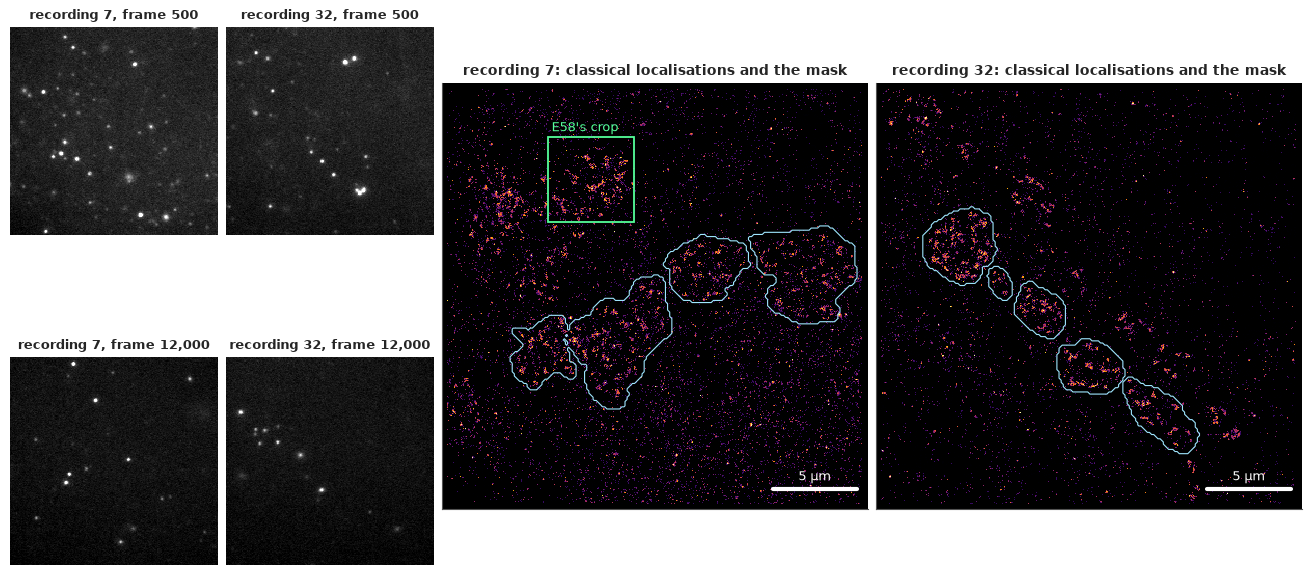

In [3]:
seconds = FRAMES * CYCLE_MS / 1000
print(f"One movie: {FRAMES:,} frames x {CYCLE_MS} ms = {seconds:.1f} s on the camera (TIFF tags, measured).")
print(f"45 junctions per channel: {45 * seconds / 3600:.1f} h of scope time and {45 * 1.2098:.0f} GB "
      "(the 45 is the paper's 22 + 23 NMJs, one recording each is our assumption).")
for n in (10500, 12000):
    print(f"  At {n:,} frames: saves {45 * seconds * (1 - n / FRAMES) / 60:.0f} min and "
          f"{45 * 1.2098 * (1 - n / FRAMES):.0f} GB per channel [extrapolated, same assumption]")

frames_shown = pack["show_frames"]
fig = plt.figure(figsize=(13, 6.6), layout="constrained")
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 2.05, 2.05])
vmin, vmax = np.percentile(pack["r7_frames"], [1, 99.9])
for row, f in enumerate(frames_shown):
    for col, rec in enumerate(RECS):
        ax = fig.add_subplot(grid[row, col])
        ax.imshow(pack[f"{rec}_frames"][row], cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_title(f"{RECS[rec]}, frame {f:,}", fontsize=9)
        ax.axis("off")
for col, rec in enumerate(RECS):
    ax = fig.add_subplot(grid[:, 2 + col])
    render = np.ma.masked_equal(pack[f"{rec}_render_chosen"].astype(float), 0)
    ax.imshow(render, cmap=DARK, norm=LogNorm(1, 60), extent=(-0.5, 199.5, 199.5, -0.5), interpolation="nearest")
    ax.contour(pack[f"{rec}_mask"], levels=[0.5], colors="#9fe6ff", linewidths=0.8)
    if rec == "r7":
        ax.add_patch(Rectangle((49.5, 24.5), 40, 40, fill=False, ec="#55ff99", lw=1.3))
        ax.text(51, 22, "E58's crop", color="#55ff99", fontsize=9)
    ax.plot([155, 155 + 5000 / PIXEL_NM], [190, 190], color="w", lw=3)
    ax.text(155 + 2500 / PIXEL_NM, 186, "5 µm", color="w", ha="center", fontsize=9)
    ax.set_title(f"{RECS[rec]}: classical localisations and the mask", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor("black");

One movie is 176 s on the camera. Stopping at 10,500 frames would save about 40 minutes and 16 GB per
channel, and stopping at 12,000 about 26 minutes and 11 GB.

The recordings are visibly different samples, and a mask is a small part of the frame: 12.8% of the pixels
in recording 7 and 7.2% in recording 32. Most of what the camera records never reaches the answer. E58's
crop lies entirely outside the mask, so its numbers and this notebook's come from different places.

The dye bleaches, and that is why a shorter movie might work at all. Here is how fast the signal runs out.

recording 7: 367,071 blobs, 83,440 in the mask (23%); first 5,000 frames hold 43%, first 10,500 hold 77%
recording 32: 245,335 blobs, 56,969 in the mask (23%); first 5,000 frames hold 44%, first 10,500 hold 78%


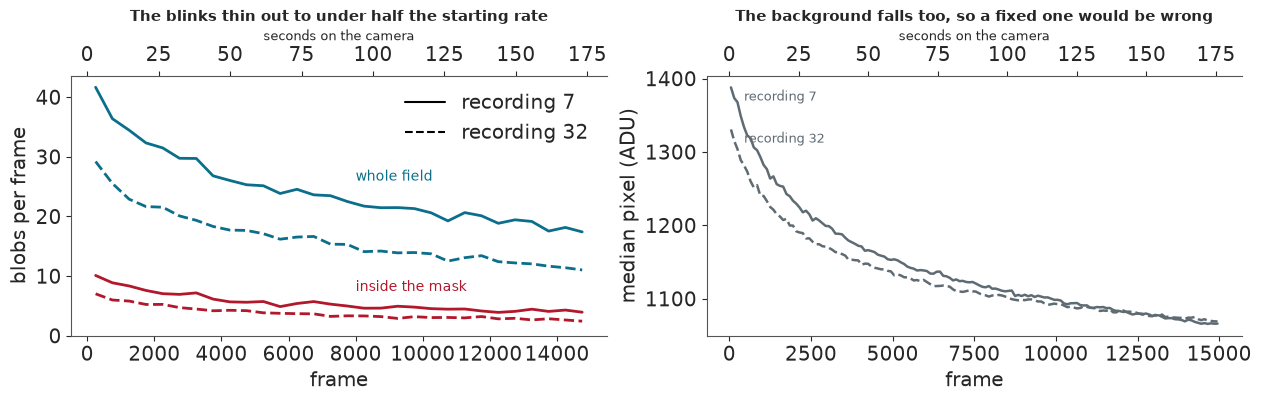

In [4]:
frames_at = (np.arange(30) + 0.5) * int(pack["block_frames"])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), layout="constrained")
for rec, style in zip(RECS, ("-", "--")):
    per_frame = pack[f"{rec}_blobs_per_block"] / pack["block_frames"]
    in_mask = pack[f"{rec}_blobs_mask_per_block"] / pack["block_frames"]
    axes[0].plot(frames_at, per_frame, style, color=CLASSICAL, lw=2)
    axes[0].plot(frames_at, in_mask, style, color=NET_A, lw=2)
    axes[1].plot((np.arange(150) + 0.5) * 100, pack[f"{rec}_median_per_100"], style, color=SINGLE, lw=1.8)
    axes[1].text(450, pack[f"{rec}_median_per_100"][0] - 3, RECS[rec], fontsize=9, color=SINGLE, va="top")
    cum = np.cumsum(pack[f"{rec}_blobs_per_block"]) / pack[f"{rec}_blobs_per_block"].sum()
    print(f"{RECS[rec]}: {pack[f'{rec}_blobs_per_block'].sum():,} blobs, {pack[f'{rec}_blobs_mask_per_block'].sum():,} "
          f"in the mask ({pack[f'{rec}_blobs_mask_per_block'].sum() / pack[f'{rec}_blobs_per_block'].sum():.0%}); "
          f"first 5,000 frames hold {cum[9]:.0%}, first 10,500 hold {cum[20]:.0%}")
axes[0].text(8000, 26, "whole field", color=CLASSICAL, fontsize=10)
axes[0].text(8000, 7.5, "inside the mask", color=NET_A, fontsize=10)
axes[0].legend(handles=[Line2D([], [], color="k", ls="-", label="recording 7"),
                        Line2D([], [], color="k", ls="--", label="recording 32")], loc="upper right")
axes[0].set(xlabel="frame", ylabel="blobs per frame", ylim=(0, None))
axes[0].set_title("The blinks thin out to under half the starting rate", fontsize=11)
axes[1].set(xlabel="frame", ylabel="median pixel (ADU)")
axes[1].set_title("The background falls too, so a fixed one would be wrong", fontsize=11)
for ax in axes:
    top = ax.secondary_xaxis("top", functions=(lambda f: f * CYCLE_MS / 1000, lambda s: s * 1000 / CYCLE_MS))
    top.set_xlabel("seconds on the camera", fontsize=9);

The detector finds 367,071 blobs in recording 7 and 245,335 in recording 32, 23% of them inside the mask.
The blink rate falls to under half its starting value, and the first 10,500 frames hold about 77% of all
blobs. The background falls too, which is why the classical pipeline subtracts a rolling background.

## 2 · The first failure: a calibration that does not hold still

A localiser needs photons, and the camera reports ADU. An EMCCD adds an offset and multiplies each
photoelectron by a gain, so the variance of a steady pixel grows in a straight line with its mean, and the
photon-transfer curve gives both numbers (E58, section 1). E58 fitted them once, on 2,000 frames. Do they
hold along a full movie and between recordings? We set the tolerance at 20 ADU and 10%, and planned to
calibrate every 500-frame block separately if it failed.

                offset moves   slope moves    line
recording 7          243 ADU           37%  20 ADU, 10%
recording 32         208 ADU           31%  20 ADU, 10%
Between the two: 83 ADU, 12%. Verdict: NO-GO, so the written action applies: calibrate per block and per recording.
Post-hoc, one line per recording across blocks: recording 7 slope 13.48, offset 434, r 0.9997; recording 32 slope 12.81, offset 413, r 0.9998. E58: slope 13.86, offset 457


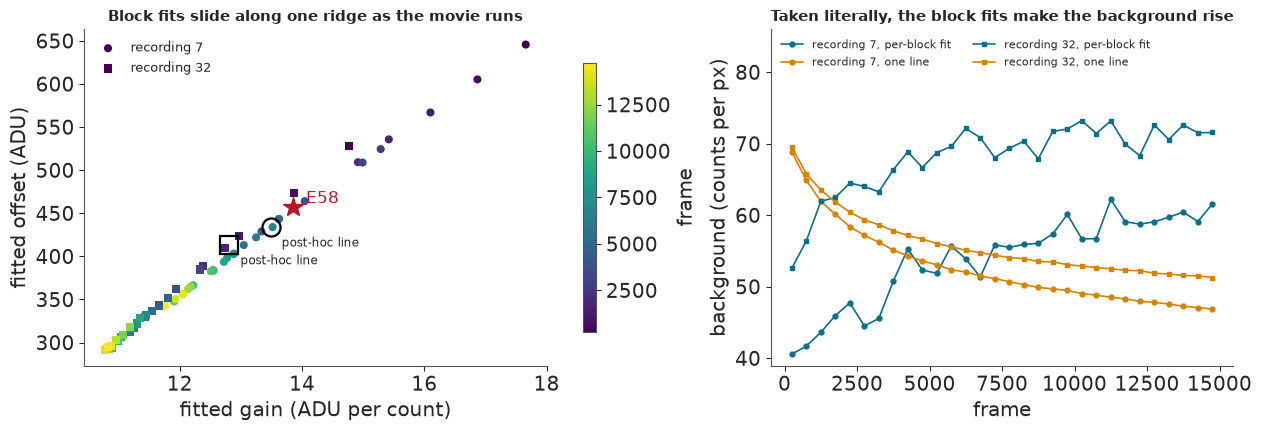

In [5]:
p3 = store.load_json("p3_calibration")
line = store.load_json("p3_line")
print(f"{'':14}{'offset moves':>14}{'slope moves':>14}{'line':>8}")
for rec in RECS:
    row = p3["recordings"][rec]
    print(f"{RECS[rec]:14}{row['offset_dev_max']:>10.0f} ADU{row['slope_rel_max']:>14.0%}{'20 ADU, 10%':>13}")
print(f"Between the two: {p3['between']['offset']:.0f} ADU, {p3['between']['slope_rel']:.0%}. Verdict: NO-GO, "
      "so the written action applies: calibrate per block and per recording.")
print("Post-hoc, one line per recording across blocks: " + "; ".join(
    f"{RECS[r]} slope {line[r]['slope']:.2f}, offset {line[r]['offset']:.0f}, r {line[r]['r']:.4f}" for r in RECS)
    + f". E58: slope {p3['e58']['slope']}, offset {p3['e58']['offset']:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), layout="constrained")
for rec, marker in zip(RECS, ("o", "s")):
    row = p3["recordings"][rec]
    slopes, offsets = np.array(row["slopes"]), np.array(row["offsets"])
    dots = axes[0].scatter(slopes, offsets, c=frames_at, cmap="viridis", marker=marker, s=34, label=RECS[rec], lw=0)
    medians = pack[f"{rec}_median_per_100"].reshape(30, 5).mean(1)
    axes[1].plot(frames_at, (medians - offsets) / slopes, marker=marker, ms=3.5, color=CLASSICAL, lw=1.2,
                 label=f"{RECS[rec]}, per-block fit")
    axes[1].plot(frames_at, (medians - line[rec]["offset"]) / line[rec]["slope"], marker=marker, ms=3.5, color=NET_B,
                 lw=1.2, label=f"{RECS[rec]}, one line")
    axes[0].plot(line[rec]["slope"], line[rec]["offset"], marker=marker, ms=13, mfc="none", mec="k", mew=1.6)
    axes[0].annotate("post-hoc line", (line[rec]["slope"], line[rec]["offset"]), xytext=(8, -14),
                     textcoords="offset points", fontsize=8.5)
axes[0].plot(p3["e58"]["slope"], p3["e58"]["offset"], "*", ms=15, color=NET_A)
axes[0].annotate("E58", (p3["e58"]["slope"], p3["e58"]["offset"]), xytext=(9, 3), textcoords="offset points", color=NET_A)
fig.colorbar(dots, ax=axes[0], label="frame", shrink=0.8)
axes[0].legend(loc="upper left", fontsize=9)
axes[0].set(xlabel="fitted gain (ADU per count)", ylabel="fitted offset (ADU)")
axes[0].set_title("Block fits slide along one ridge as the movie runs", fontsize=11)
axes[1].legend(fontsize=8, loc="upper left", ncols=2)
axes[1].set(xlabel="frame", ylabel="background (counts per px)", ylim=(None, 86))
axes[1].set_title("Taken literally, the block fits make the background rise", fontsize=11);

They fail by a wide margin. Along recording 7 the fitted offset moves by 243 ADU and the gain by 37%,
along recording 32 by 208 ADU and 31%, and the two recordings differ by 83 ADU and 12%.

Read the right panel. The raw background falls throughout the movie, yet the per-block calibration turns
it into a background that climbs, which is not physically plausible. The left panel suggests why: within a
block the pixel values span a narrow range, and the fit trades offset against gain along a ridge. Across
blocks, block mean against block variance falls on one straight line per recording (r of 0.9997-0.9998),
with gains of 13.5 and 12.8 close to E58's 13.9.

So there are two calibrations, and neither is settled. We keep both. Per-block calibration is the main
analysis; the single line per recording, which we only looked for after the per-block fit failed, is the
more plausible and runs alongside it. The difference turns out to matter.

## 3 · The classical answer: how many frames?

This is the main result of the notebook, and it uses no network. E58's fitter ran over both movies, 3-4
minutes each on 13 CPUs. Rows with a posterior sd under 30 nm were kept, drift was corrected, and
localisations linked in consecutive frames were merged into events. We recompute the rule live from the
stored points, check that it reproduces every stored answer, and then vary it.

In [6]:
def n_star(curve, allowance=0.10):
    """Smallest N on the grid where FRC, count and band agree with 15,000, there and at every larger N."""
    points, bands = curve["points"], curve["bands"]
    full, top = points["15000"], bands["15000"]

    def overlap(q, r):
        return q[0] <= r[1] and r[0] <= q[1]

    answer = FRAMES
    for N in reversed(GRID):
        p, q = points[str(N)], bands[str(N)]
        fine = (abs(p["frc_nm"] / full["frc_nm"] - 1) <= allowance and abs(p["count"] / full["count"] - 1) <= allowance
                and overlap(q["frc_q"], top["frc_q"]) and overlap(q["count_q"], top["count_q"]))
        if not fine:
            break
        answer = N
    return answer


def n_both(name, allowance=0.10):
    return max(n_star(decisions[name][rec], allowance) for rec in RECS)


for name in decisions:
    for rec in RECS:
        assert n_star(decisions[name][rec]) == decisions[name][rec]["N_star"], (name, rec)
print("Live rule matches every stored N*, across", len(decisions), "curve sets and both recordings.\n")
rows = []
for N in (2000, 5000, 7500, 9000, 10500, 12000, 15000):
    row = {"frames": N}
    for rec in RECS:
        p = decisions["classical"][rec]["points"][str(N)]
        c = decisions["classical"][rec]["checks"][str(N)]
        row[f"{rec} FRC nm"], row[f"{rec} clusters"], row[f"{rec} all three"] = round(p["frc_nm"], 1), int(p["count"]), c["all"]
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print("\nN*, recording 7 / recording 32 / both, classical:")
print(f"  per block (written action, gated):  {decisions['classical']['r7']['N_star']:,} / "
      f"{decisions['classical']['r32']['N_star']:,} / {n_both('classical'):,}")
print(f"  one line (post-hoc sensitivity):    {decisions['classical_line']['r7']['N_star']:,} / "
      f"{decisions['classical_line']['r32']['N_star']:,} / {n_both('classical_line'):,}")
print("\nWhat the 10% allowance does to N for both, per block, then line:")
for allowance in (0.05, 0.075, 0.10, 0.125, 0.15, 0.20):
    print(f"  {allowance:>5.1%}: {n_both('classical', allowance):>6,} {n_both('classical_line', allowance):>7,}")

frames_boot = posthoc["frames"]
print("\nPost-hoc, count rule only, classical, 100 block-bootstrap draws (200-frame blocks):")
for key, title in (("per_block", "per block"), ("line", "one line")):
    row = frames_boot["calibrations"][key]
    low, high = row["both_95"]
    print(f"  {title:10} N for both, 95% range {low:,.0f}-{high:,.0f}. Draws at each N: " + ", ".join(f"{int(n):,}: {k}" for n, k in row["both_counts"].items())
          + f". Recording 32 alone: {min(row['r32']['stars']):,}-{max(row['r32']['stars']):,}")
margins = {int(k): v["margin"] for k, v in frames_boot["band_seeds"].items()}
print("Band overlap at 10,500 of recording 7's count, in clusters, stored seed then five fresh families: "
      + ", ".join(f"{margins[k]:+.1f}" for k in (88, 1, 2, 3, 4, 5)) + ". A negative margin fails the test. FRC's band was not repeated.")
row = frames_boot["calibrations"]["per_block"]["r7"]
print(f"Recording 7, first N frames:           {row['points']}")
print(f"Same event count, thinned from all 15,000: {row['thinned']} (one thinning at each N)")
print(f"10,500 frames hold {row['events'][7] / row['events'][-1]:.0%} of recording 7's events")

Live rule matches every stored N*, across 10 curve sets and both recordings.

 frames  r7 FRC nm  r7 clusters  r7 all three  r32 FRC nm  r32 clusters  r32 all three
   2000       32.8          381         False        41.5           272          False
   5000       34.1          603         False        42.9           328          False
   7500       34.7          699         False        42.6           345           True
   9000       36.1          715         False        42.6           337           True
  10500       36.1          732          True        41.2           351           True
  12000       36.7          764          True        41.2           372           True
  15000       35.3          801          True        41.2           374           True

N*, recording 7 / recording 32 / both, classical:
  per block (written action, gated):  10,500 / 7,500 / 10,500
  one line (post-hoc sensitivity):    12,000 / 5,000 / 12,000

What the 10% allowance does to N for both, per blo

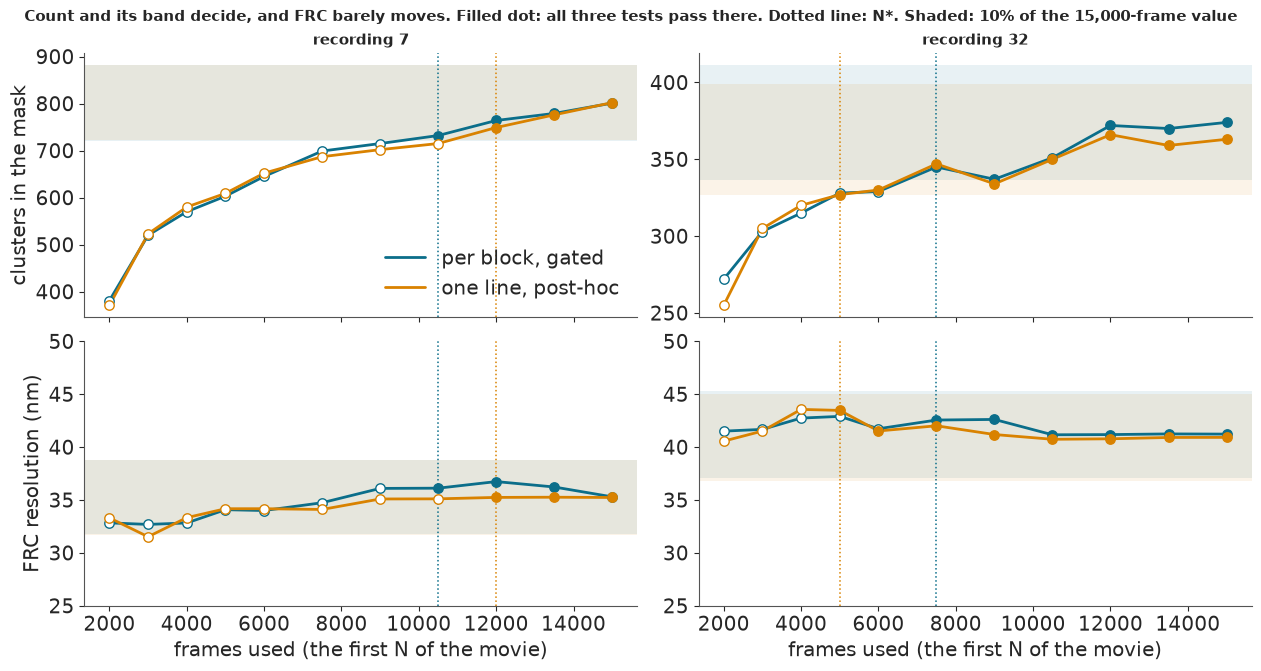

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.6), sharex=True, layout="constrained")
for col, rec in enumerate(RECS):
    for name, colour, label in (("classical", CLASSICAL, "per block, gated"), ("classical_line", NET_B, "one line, post-hoc")):
        curve = decisions[name][rec]
        frc = np.array([curve["points"][str(N)]["frc_nm"] for N in GRID])
        count = np.array([curve["points"][str(N)]["count"] for N in GRID])
        ok = np.array([curve["checks"][str(N)]["all"] for N in GRID])
        for row, y in enumerate((count, frc)):
            ax = axes[row, col]
            ax.plot(GRID, y, color=colour, lw=2, label=label)
            ax.scatter(np.array(GRID)[ok], y[ok], s=46, color=colour, zorder=3)
            ax.scatter(np.array(GRID)[~ok], y[~ok], s=46, facecolor="w", edgecolor=colour, zorder=3)
            ax.axhspan(y[-1] * 0.9, y[-1] * 1.1, color=colour, alpha=0.09, lw=0)
            ax.axvline(curve["N_star"], color=colour, lw=1.1, ls=":")
    axes[0, col].set_title(RECS[rec], fontsize=11)
    axes[1, col].set_xlabel("frames used (the first N of the movie)")
axes[0, 0].set_ylabel("clusters in the mask")
axes[1, 0].set_ylabel("FRC resolution (nm)")
axes[1, 0].set_ylim(25, 50)
axes[1, 1].set_ylim(25, 50)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Count and its band decide, and FRC barely moves. Filled dot: all three tests pass there. Dotted line: N*. "
             "Shaded: 10% of the 15,000-frame value", fontsize=11);

Under the rule as fixed, the answer is **10,500 frames, 30% fewer than 15,000**: recording 7 needs 10,500
and recording 32 only 7,500. Under the one-line calibration it is 12,000, with recording 32 at 5,000.

**FRC is no help.** Recording 7 reads 32.8 nm at 2,000 frames and 35.3 nm at 15,000, so more frames did
not improve it. The count does all the work, and in recording 7 it never levels off: it rises 9% from
10,500 frames to 15,000. N comes from where the curve enters the 10% band, so a tighter allowance pushes
it up (5% gives 12,000).

**The margin at 10,500 is narrow.** At 9,000 frames the count misses its band by only 6 clusters, and at
10,500 the bootstrap bands of recording 7's count overlap by 11 clusters. Repeating that bootstrap with
five fresh seeds gave a margin of +8 to +11 four times and -10 once, and a failure would make N 12,000. So
12,000 is the safer end.

**Sampling noise is wider than the gap between the calibrations.** A block bootstrap of the count rule,
added after these results, puts N for both recordings between 7,500 and 13,500 under either calibration,
with almost the same spread of draws. So this run cannot show that calibration moves N at all. Recording
32 alone ranges from 2,000 to 12,000.

**The rule measures events, not settling.** Thin all 15,000 frames at random to the same number of events
and the cluster curve barely changes (743 clusters against 732 at 10,500). Frame order carries almost
nothing, so "10,500 frames" really means "about 77% of the events". The bootstrap bands are not intervals
around the points, since each draw adds the localisation error a second time (889-989 clusters against a
point of 801 at 15,000 frames), but the test compares bands with bands, so it stands.

## 4 · Is there anything for a network to find?

E58's headline was that overlapping emitters cost a classical pipeline recall: 0.758 even with Bayesian
model selection, at 0.70 emitters per µm². If the real movies were that dense, a network might separate
spots that fitters merge. So before training anything, we asked how often a blob in the mask has a
neighbour closer than 4 px, set "rare" at under 5% in both recordings, and planned to stop before the full
network run if it was rare.

                                             rec 7  rec 32  status
Written primary: 4-8 px annulus, scaled      2.18%   1.65%  gated
Detector, direct (merging hides most)        0.41%   0.35%  lower bound
Poisson at mask density                      5.31%   6.44%  ignores clustering
Neighbour 1.5-4 px, frame 200 away           5.23%   6.86%  post-hoc
Neighbour under 4 px, frame 200 away         7.42%   9.06%  post-hoc, upper side
Two bright emitters in a fit                26.41%  33.82%  inflated by misfit
Fit chose K of 2 or more                    49.32%  52.23%  inflated by misfit

E58's dense simulation, same Poisson sum at 0.70 per um^2: 43% [extrapolated]
Written verdict: RARE, so the stop before FULL fired.


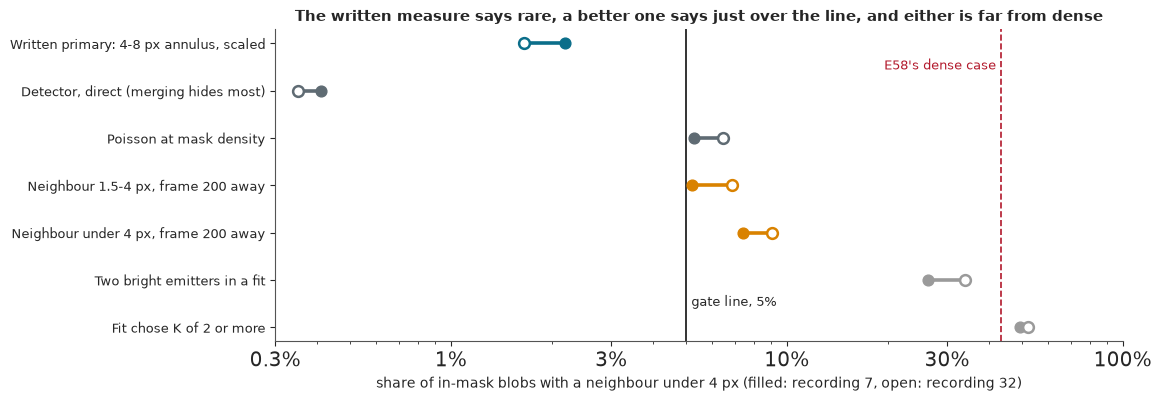

In [8]:
over = {rec: decisions["classical"][rec]["overlap"] for rec in RECS}
rows = [("Written primary: 4-8 px annulus, scaled", [decisions["classical"]["overlap_primary"][r] for r in RECS], "gated", CLASSICAL),
        ("Detector, direct (merging hides most)", [over[r]["all"]["detector_under_4"] for r in RECS], "lower bound", SINGLE),
        ("Poisson at mask density", [over[r]["poisson_basis"]["share_under_4"] for r in RECS], "ignores clustering", SINGLE),
        ("Neighbour 1.5-4 px, frame 200 away", [overlap_posthoc[r]["gap200"]["px_1p5_to_4"] for r in RECS], "post-hoc", NET_B),
        ("Neighbour under 4 px, frame 200 away", [overlap_posthoc[r]["gap200"]["under_4"] for r in RECS], "post-hoc, upper side", NET_B),
        ("Two bright emitters in a fit", [over[r]["share_two_bright_1_4px"] for r in RECS], "inflated by misfit", MUTED),
        ("Fit chose K of 2 or more", [over[r]["share_K2plus"] for r in RECS], "inflated by misfit", MUTED)]
print(f"{'':42}{'rec 7':>8}{'rec 32':>8}  status")
for label, values, status, _ in rows:
    print(f"{label:42}{values[0]:>8.2%}{values[1]:>8.2%}  {status}")
dense = 1 - np.exp(-0.70 * np.pi * (4 * PIXEL_NM / 1000) ** 2)
print(f"\nE58's dense simulation, same Poisson sum at 0.70 per um^2: {dense:.0%} [extrapolated]")
assert decisions["classical"]["overlap_rare"], "the written verdict"
print("Written verdict: RARE, so the stop before FULL fired.")

fig, ax = plt.subplots(figsize=(11.5, 3.9), layout="constrained")
for i, (label, values, status, colour) in enumerate(rows[::-1]):
    ax.plot(values, [i, i], color=colour, lw=2.6, zorder=2)
    ax.scatter(values[0], i, s=60, color=colour, zorder=3)
    ax.scatter(values[1], i, s=60, facecolor="w", edgecolor=colour, lw=1.8, zorder=3)
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]], fontsize=9.5)
ax.axvline(0.05, color=LINE_COL, lw=1.2)
ax.text(0.052, 0.45, "gate line, 5%", fontsize=9)
ax.axvline(dense, color=NET_A, lw=1.2, ls="--")
ax.text(dense * 0.97, 5.45, "E58's dense case", fontsize=9, color=NET_A, ha="right")
ax.set_xscale("log")
ax.set_xticks([0.003, 0.01, 0.03, 0.1, 0.3, 1], ["0.3%", "1%", "3%", "10%", "30%", "100%"])
ax.set(xlim=(0.003, 1))
ax.set_xlabel("share of in-mask blobs with a neighbour under 4 px (filled: recording 7, open: recording 32)", fontsize=10)
ax.set_title("The written measure says rare, a better one says just over the line, and either is far from dense", fontsize=11);

The measure we fixed in advance gives 2.2% and 1.65%: rare. It is a lower bound, and further below the
truth than we expected, because its annulus reaches outside narrow boutons. Pairing each blob with
neighbours from a frame 200 away keeps the clustering and avoids detector merging, and this later measure
gives about 5-9%. E58's dense setting gives 43%, so either way the real movies are far from dense. The
rows built from fits read high because a fit adds emitters to absorb misfit: on a simulated control the
same $K$ measure read 18% when 11.5% of emitters truly had a near neighbour.

So there is little for a network to find here, and small pilot runs had already shown problems (section
9). We train the full network anyway: a failure on real data, checked carefully, teaches more than a
success on simulation.

## 5 · The instrument, and what it cost to build

The network follows DECODE (Speiser et al. 2021, *Nature Methods* 18:1082), written fresh from the paper.
Training uses no real data: a simulator draws emitters and camera noise, and the loss asks the network to
recover them. **So the network learns its simulator.** The training code is in `tools/run_e88_net.py`. The
wall times below are inflated, because the job shared the machine; hatched bars are extrapolated from a
measured rate.

Network A: 40,000 steps in 817 s, 48.9 steps/s, 0.26 GB VRAM, 471,784 weights, deterministic ops
Network B: 12,000 steps in 253 s, 47.4 steps/s, 0.27 GB VRAM, warm start from A
Inference: 8 movies, 120,000 frames, 183 s of prediction at 571-748 frames/s, 2.52 GB VRAM
Pilot P4, without deterministic ops: GPU 203 steps/s on 0.76 GB, CPU 4.66 steps/s on 13 CPUs: 44x. A pilot rate: the planned full CPU comparison was skipped.
Classical: 4 runs in 13.4 min on 13 CPUs (one recording-7 run covers 28 of 30 blocks)


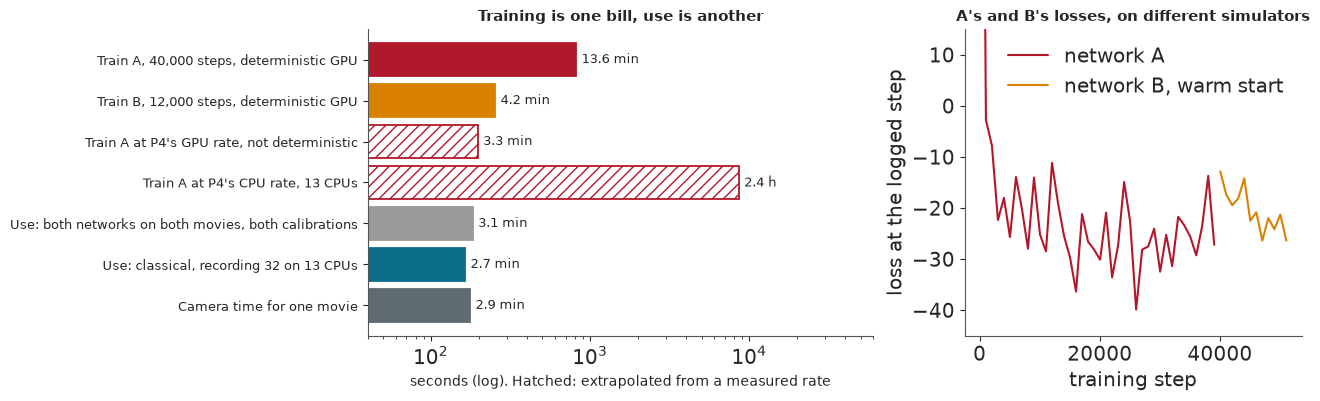

In [9]:
train, infer = summary["train"], summary["infer"]
p4_gpu, p4_cpu = store.load_json("p4_gpu"), store.load_json("p4_cpu")
inference_s = sum(row["predict_seconds"] for net in infer.values() for row in net.values())
rates = sorted(row["frames_per_s"] for net in infer.values() for row in net.values())
classical_s = [store.load_json(f"classical_{r}_timing")["seconds"] for r in ("r7", "r32", "line_r7", "line_r32")]
ratio = p4_gpu["steps_per_s"] / p4_cpu["steps_per_s"]
print(f"Network A: {train['a']['steps']:,} steps in {train['a']['seconds']:.0f} s, {train['a']['steps_per_s']:.1f} steps/s, "
      f"{train['a']['vram']['peak_gb']:.2f} GB VRAM, {train['a']['weights']:,} weights, deterministic ops")
print(f"Network B: {train['b']['steps']:,} steps in {train['b']['seconds']:.0f} s, {train['b']['steps_per_s']:.1f} steps/s, "
      f"{train['b']['vram']['peak_gb']:.2f} GB VRAM, warm start from A")
print(f"Inference: 8 movies, 120,000 frames, {inference_s:.0f} s of prediction at {rates[0]:.0f}-{rates[-1]:.0f} frames/s, "
      f"{max(r['vram']['peak_gb'] for n in infer.values() for r in n.values()):.2f} GB VRAM")
print(f"Pilot P4, without deterministic ops: GPU {p4_gpu['steps_per_s']:.0f} steps/s on {p4_gpu['vram']['peak_gb']:.2f} GB, "
      f"CPU {p4_cpu['steps_per_s']:.2f} steps/s on 13 CPUs: {ratio:.0f}x. A pilot rate: the planned full CPU comparison was skipped.")
print(f"Classical: 4 runs in {sum(classical_s) / 60:.1f} min on 13 CPUs (one recording-7 run covers 28 of 30 blocks)")

bars = [("Train A, 40,000 steps, deterministic GPU", train["a"]["seconds"], False, NET_A),
        ("Train B, 12,000 steps, deterministic GPU", train["b"]["seconds"], False, NET_B),
        ("Train A at P4's GPU rate, not deterministic", 40000 / p4_gpu["steps_per_s"], True, NET_A),
        ("Train A at P4's CPU rate, 13 CPUs", 40000 / p4_cpu["steps_per_s"], True, NET_A),
        ("Use: both networks on both movies, both calibrations", inference_s, False, MUTED),
        ("Use: classical, recording 32 on 13 CPUs", classical_s[1], False, CLASSICAL),
        ("Camera time for one movie", seconds, False, SINGLE)]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), width_ratios=[1.5, 1], layout="constrained")
ax = axes[0]
for i, (label, value, extra, colour) in enumerate(bars[::-1]):
    ax.barh(i, value, color="none" if extra else colour, edgecolor=colour, hatch="///" if extra else None, lw=1.3)
    ax.text(value * 1.08, i, f"{value / 60:.1f} min" if value < 3600 else f"{value / 3600:.1f} h", va="center", fontsize=9)
ax.set_yticks(range(len(bars)), [b[0] for b in bars[::-1]], fontsize=9.3)
ax.set_xscale("log")
ax.set(xlim=(40, 60000))
ax.set_xlabel("seconds (log). Hatched: extrapolated from a measured rate", fontsize=10)
ax.set_title("Training is one bill, use is another", fontsize=11)
ax = axes[1]
ax.plot(train["a"]["log_steps"], train["a"]["log"], color=NET_A, lw=1.5, label="network A")
ax.plot(np.array(train["b"]["log_steps"]) + 40000, train["b"]["log"], color=NET_B, lw=1.5, label="network B, warm start")
ax.set(xlabel="training step", ylabel="loss at the logged step", ylim=(-45, 15))
ax.set_title("A's and B's losses, on different simulators", fontsize=11)
ax.legend(loc="upper right");

**Training and use are different bills.** Network A took 40,000 steps in 14 minutes, B 12,000 more in 4.
In a pilot the GPU ran 44 times faster than 13 CPUs (203 against 4.7 steps per second), and about 10 times
at the deterministic setting used here; both are pilot rates. Use is cheap: 120,000 frames went through in
about 3 minutes, 20-26 s per movie. Whoever trains the network pays once; every user inherits a
certificate or the lack of one.

**The compute was never the hard part.** Training used under 0.3 GB of a 24 GB card and the GPU work adds
up to about 21 minutes. **Reproducibility cost more:** two identical GPU runs differed by step 50, so a
stop-and-resume test failed until we switched to deterministic GPU operations, at 3.4 times the time per
step.

## 6 · A pass on simulation, and the certificate

On simulated frames the truth is known, so we can ask whether the network finds the emitters (recall) and
how close its error is to the Cramér-Rao lower bound (CRLB), the best any unbiased estimator can do (E58,
section 4). We count the network as good enough if it finds at least 90% of emitters at no more than 1.3
times the CRLB at 2,000 photons. After 5,000 steps it fell just short, at 1.38, and we trained it longer.
The figure shows the
coverage of the networks' 95% intervals over brightness and density in two simulated worlds: A's simple
one and B's empirical one.

                network  recall  x CRLB  median sd px  recall, E58 brightness  x CRLB, E58 brightness  recall, dense  x CRLB, dense
5,000 steps (P5, NO-GO)   0.989   1.379         0.050                   0.974                   1.770          0.908          2.588
        A, 40,000 steps   0.994   1.158         0.062                   0.986                   1.681          0.951          2.222
         B, 12,000 more   0.993   1.234         0.063                   0.981                   1.780          0.928          2.825
     small, 1,500 steps   0.981   1.843         0.067                   0.805                   1.861          0.671          3.357

Lines at 2,000 photons, sparse: recall 0.90, 1.3 x CRLB. CRLB here 0.061 px, 7.8 nm.
network A in the gauss world: 13 of 16 cells in the prior have 95% coverage within 0.90-0.98
network A in the empirical world: 8 of 16 cells in the prior have 95% coverage within 0.90-0.98
network B in the gauss world: 8 of 16 cells in the prior have 95%

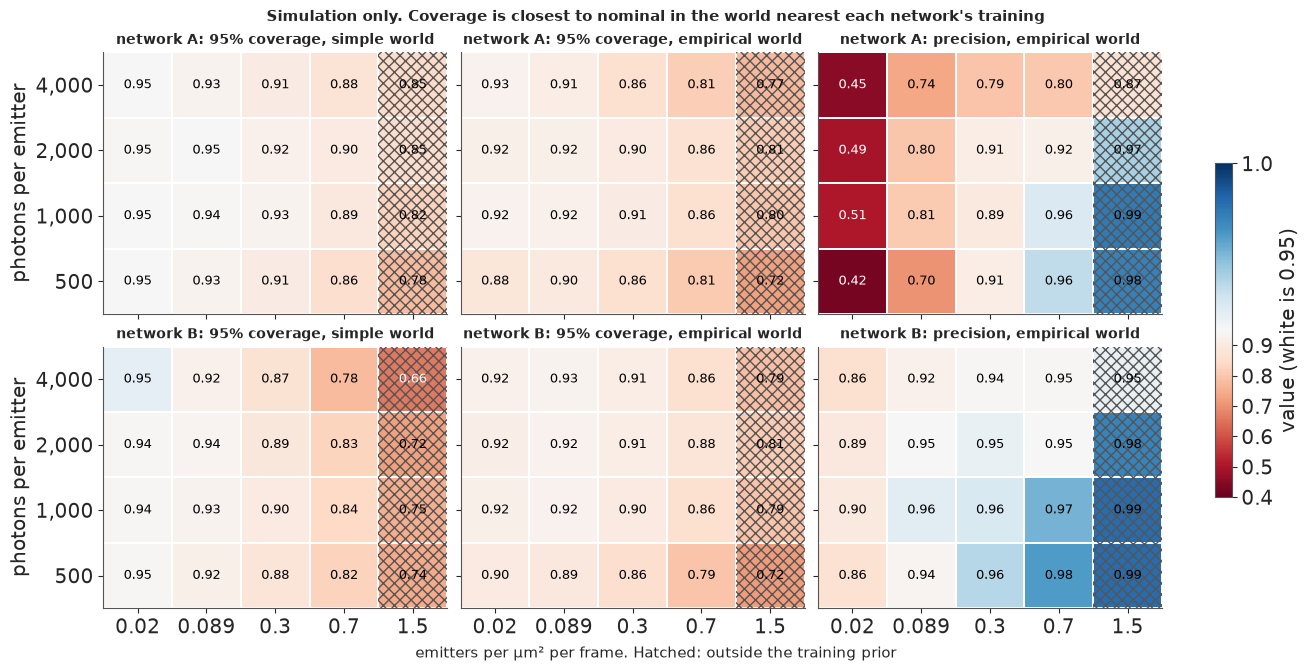

In [10]:
p5 = {"5,000 steps (P5, NO-GO)": store.load_json("p5_p5"), "A, 40,000 steps": store.load_json("p5_a"),
      "B, 12,000 more": store.load_json("p5_b"), "small, 1,500 steps": store.load_json("p5_small")}
rows = []
for name, r in p5.items():
    sparse, bright, dense_run = r["sparse_2000"], r["sparse_e58_brightness"], r["dense_e58_brightness"]
    rows.append({"network": name, "recall": sparse["tol2.0"]["recall"], "x CRLB": sparse["rmse_over_crlb"],
                 "median sd px": sparse["median_sd_px"], "recall, E58 brightness": bright["tol2.0"]["recall"],
                 "x CRLB, E58 brightness": bright["rmse_over_crlb"], "recall, dense": dense_run["tol2.0"]["recall"],
                 "x CRLB, dense": dense_run["rmse_over_crlb"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nLines at 2,000 photons, sparse: recall 0.90, 1.3 x CRLB. CRLB here {p5['A, 40,000 steps']['crlb_px']:.3f} px, "
      f"{p5['A, 40,000 steps']['crlb_nm']:.1f} nm.")


def cells(net, world, field):
    table = [r for r in certificate["simulation"][net] if r["world"] == world]
    photons, densities = sorted({r["photons"] for r in table}), sorted({r["density"] for r in table})
    out = np.full((len(photons), len(densities)), np.nan)
    for r in table:
        out[photons.index(r["photons"]), densities.index(r["density"])] = r[field]
    return out, photons, densities


def near_nominal(net, world):
    table = [r for r in certificate["simulation"][net] if r["world"] == world and r["in_prior"]]
    return sum(0.90 <= r["coverage95"] <= 0.98 for r in table), len(table)


fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True, sharey=True, layout="constrained")
views = (("gauss", "coverage95", "95% coverage, simple world"), ("empirical", "coverage95", "95% coverage, empirical world"),
         ("empirical", "precision", "precision, empirical world"))
for row, net in enumerate(("a", "b")):
    for col, (world, field, title) in enumerate(views):
        ax = axes[row, col]
        values, photons, densities = cells(net, world, field)
        norm = TwoSlopeNorm(0.95, 0.40, 1.0)
        mesh = ax.pcolormesh(np.arange(6), np.arange(5), values, cmap="RdBu", norm=norm, edgecolor="w", lw=1.2)
        for i in range(4):
            for j in range(5):
                ax.text(j + 0.5, i + 0.5, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                        color="w" if abs(values[i, j] - 0.95) > 0.28 else "k")
        ax.add_patch(Rectangle((4, 0), 1, 4, fill=False, hatch="xxx", ec="#555555", lw=0))
        ax.set_title(f"{NAME[net]}: {title}", fontsize=10)
        ax.set_xticks(np.arange(5) + 0.5, [f"{d:g}" for d in densities])
        ax.set_yticks(np.arange(4) + 0.5, [f"{p:,.0f}" for p in photons])
    axes[row, 0].set_ylabel("photons per emitter")
fig.supxlabel("emitters per µm² per frame. Hatched: outside the training prior", fontsize=10.5)
fig.colorbar(mesh, ax=axes, shrink=0.6, label="value (white is 0.95)")
fig.suptitle("Simulation only. Coverage is closest to nominal in the world nearest each network's training", fontsize=11)
for net in ("a", "b"):
    for world in ("gauss", "empirical"):
        print(f"{NAME[net]} in the {world} world: {near_nominal(net, world)[0]} of {near_nominal(net, world)[1]} "
              "cells in the prior have 95% coverage within 0.90-0.98")
emp_a = [r for r in certificate["simulation"]["a"] if r["world"] == "empirical" and r["in_prior"]]
emp_b = [r for r in certificate["simulation"]["b"] if r["world"] == "empirical" and r["in_prior"]]
print(f"Empirical world, in the prior: A precision under 0.9 in {sum(r['precision'] < 0.9 for r in emp_a)} of 16, lowest "
      f"{min(r['precision'] for r in emp_a):.2f}; B in {sum(r['precision'] < 0.9 for r in emp_b)} of 16, with recall under "
      f"0.9 in {sum(r['recall'] < 0.9 for r in emp_b)}")
own = [r for r in certificate["simulation"]["a"] if r["world"] == "gauss" and r["density"] == 0.7 and r["photons"] in (2000, 4000)]
print(f"A in its own world at 0.70 per um^2, 2,000-4,000 photons: {min(r['rmse_over_crlb'] for r in own):.1f}-"
      f"{max(r['rmse_over_crlb'] for r in own):.1f} x CRLB");

Taken alone, the table is a success. At 40,000 steps A finds 99.4% of emitters at 1.16 times the CRLB, and
B 99.3% at 1.23 times. In the dense movie both fall to 2.2-2.8 times. The 5,000-step miss still counts:
more training is not the same as passing the check you set.

**That is the trap: a simulation pass says the network learned the simulator.** In its own world A has 95%
coverage within 0.90-0.98 in 13 of 16 cells. Move it to B's world, still a simulation, and that drops to
8, and its precision falls as low as 0.42, so most of its detections there match nothing. B repairs much
of that in its own world, at some cost in recall. Neither result touches the microscope. The 5,000-step
network also predicted a median sd of 0.050 px, below the CRLB of 0.061 px, which no unbiased estimator
can sustain; at 40,000 steps A's sd sits at the CRLB. Section 7 asks whether that lasts on real frames.

## 7 · Real frames: the four checks

Here is what no training loss can see. Every check runs inside the masks, and recording 32, which played
no part in training, is the one that counts.

### The PSF that B was built on

B's simulator used a point spread function (PSF) stacked from 20,000 bright spots of recording 7. As
stored, it puts a quarter of the light beyond 3 px, against 2.3% for a Gaussian. Is that the real PSF? A
control added afterwards answers it: repeat the stack where the emitter has gone, at the same sites later
or at random sites, and subtract.

20,000 spots of 30,888: 24.7% of energy beyond 3 px against 2.3% for a 1.05 px Gaussian; peak 0.097 against 0.144; sd of log width 0.118, which includes fit noise
Post-hoc control on the same 20,000 spots. Stack: light over N 1.34, 23.4% beyond 3 px counted out to 9 px
  same sites, 100 frames away  leaves 0.32 of N, flat 0.0011 per px² at 3-8 px, core 0.0038. Stack minus this: light over N 1.02, 5.8% beyond 3 px, peak 0.114
  same sites, 300 frames away  leaves 0.31 of N, flat 0.0012 per px² at 3-8 px, core 0.0031. Stack minus this: light over N 1.02, 5.2% beyond 3 px, peak 0.114
  random sites, same frames    leaves 0.23 of N, flat 0.0009 per px² at 3-8 px, core 0.0008. Stack minus this: light over N 1.11, 10.0% beyond 3 px, peak 0.111
Width scale of a spot: median 0.84, log sd 0.116 with the stored fit; 0.96, 0.132 with a free amplitude


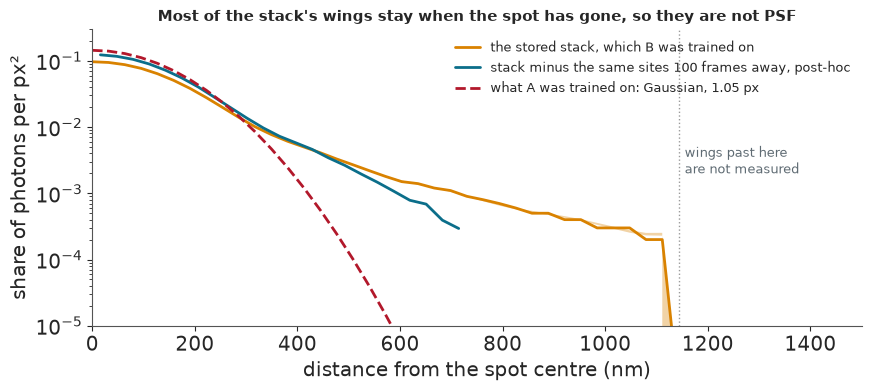

In [11]:
psf = store.load_json("psf_bg")
knots, profile = np.array(psf["knots_px"]), np.array(psf["profile"])
sigma = 1.05
gauss = np.exp(-knots**2 / (2 * sigma**2)) / (2 * np.pi * sigma**2)
print(f"{psf['spots']:,} spots of {psf['pool']:,}: {psf['share_beyond_3px']:.1%} of energy beyond 3 px against "
      f"{psf['share_beyond_3px_gauss_105']:.1%} for a {sigma} px Gaussian; peak {psf['peak']:.3f} against "
      f"{psf['peak_gauss_105']:.3f}; sd of log width {psf['log_w_sd']:.3f}, which includes fit noise")
psf_control = posthoc["psf"]
print(f"Post-hoc control on the same {psf_control['spots']:,} spots. Stack: light over N {psf_control['stack_integral']:.2f}, "
      f"{psf_control['stack_share_signed']:.1%} beyond 3 px counted out to 9 px")
for name, title in (("after_100", "same sites, 100 frames away"), ("after_300", "same sites, 300 frames away"), ("random_sites", "random sites, same frames")):
    row = psf_control["controls"][name]
    print(f"  {title:28} leaves {row['integral_control']:.2f} of N, flat {row['pedestal_3_to_8px']:.4f} per px² at 3-8 px, core {row['core_under_1px']:.4f}. "
          f"Stack minus this: light over N {row['integral_difference']:.2f}, {row['share_difference']:.1%} beyond 3 px, peak {row['peak_difference']:.3f}")
width = psf_control["width"]
print(f"Width scale of a spot: median {width['stored_rule_median']:.2f}, log sd {width['stored_rule_log_sd']:.3f} with the stored fit; "
      f"{width['amplitude_free_median']:.2f}, {width['amplitude_free_log_sd']:.3f} with a free amplitude")
centres = (np.arange(len(psf_control["raw"])) + 0.5) * psf_control["knots_px"][1]
after = psf_control["controls"]["after_100"]
clean = np.array(after["difference"]) / after["integral_difference"]
fig, ax = plt.subplots(figsize=(8.6, 3.8), layout="constrained")
ax.fill_between(knots * PIXEL_NM, np.maximum(pack["psf_band"][0], 1e-6), pack["psf_band"][1], color=NET_B, alpha=0.35, lw=0)
ax.plot(knots * PIXEL_NM, np.maximum(profile, 1e-6), color=NET_B, lw=2, label="the stored stack, which B was trained on")
ax.plot(centres * PIXEL_NM, np.where(clean > 0, clean, np.nan), color=CLASSICAL, lw=2, label="stack minus the same sites 100 frames away, post-hoc")
ax.plot(knots * PIXEL_NM, gauss, color=NET_A, lw=2, ls="--", label="what A was trained on: Gaussian, 1.05 px")
ax.axvline(9 * PIXEL_NM, color=MUTED, lw=1, ls=":")
ax.text(9 * PIXEL_NM + 12, 0.002, "wings past here\nare not measured", fontsize=9, color=SINGLE)
ax.set_yscale("log")
ax.set(ylim=(1e-5, 0.3), xlim=(0, 1500), xlabel="distance from the spot centre (nm)", ylabel="share of photons per px²")
ax.set_title("Most of the stack's wings stay when the spot has gone, so they are not PSF", fontsize=11)
ax.legend(loc="upper right", fontsize=9);

**The wing is mostly a contaminant.** Random sites leave a flat pedestal holding 0.23 of the spot's photon
count, and the same sites 100 frames later leave 0.32, because bright spots sit where other molecules sit.
Subtract that, and the light sums to 1.02 of the photon count, with 5-6% beyond 3 px. The real PSF has
some wing, but nowhere near a quarter. **So B was trained on a contaminated PSF, not the real one**, with
about 15-20% of each emitter's light in wings that are not PSF. We did not measure how much that explains
of B's results below.

### Check 1: the paired-frame test

How do you test error bars with no ground truth? A molecule that stays on across frames gives two
estimates of the same point. If the sds are honest, the standardised difference

$$z = \frac{\hat x_1 - \hat x_2}{\sqrt{\sigma_1^2 + \sigma_2^2}}$$

is standard normal, so the sd of $z$ over many pairs should be 1; above 1, the error bars are too small.
We link detections 3 frames apart, because the network reads 3 frames at a time and a gap of 1 would let
both estimates share pixels. A mixture allows for false links, and every method is weighted to the
brightness of the classical chosen-$K$ fit, since $z$ depends on brightness. Honest error bars give an sd
of $z$ near 1; we call 1.0-1.15 good and anything above 1.25 a failure. Because the classical fitter might
fail that too, we also ask a relative question: is the network no worse than classical? The test cannot see
a bias shared by both frames, so passing it would be necessary, not sufficient.

                         where     A  A 95% half  A 1 se     B  B 95% half  B 1 se  classical  K = 1  K = 1, own basis         absolute                relative
          recording 32, judged 1.399       0.031   0.016 1.631       0.034   0.017      1.633  1.427             1.487 failure, failure no worse than classical
                   recording 7 1.267       0.016   0.008 1.387       0.020   0.010      1.429  1.302             1.340 failure, failure no worse than classical
recording 32, line calibration 1.386       0.030   0.016 1.606       0.032   0.017      1.626  1.413             1.470 failure, failure no worse than classical
 recording 7, line calibration 1.283       0.015   0.008 1.429       0.019   0.010      1.444  1.307             1.344 failure, failure no worse than classical

Simulated baseline, gap 3, unweighted, whole field: network A 1.02, network B 1.08, classical, chosen K 1.13, classical, K = 1 1.06
It tests the method. It says nothing of the microscope.
Post-hoc, p

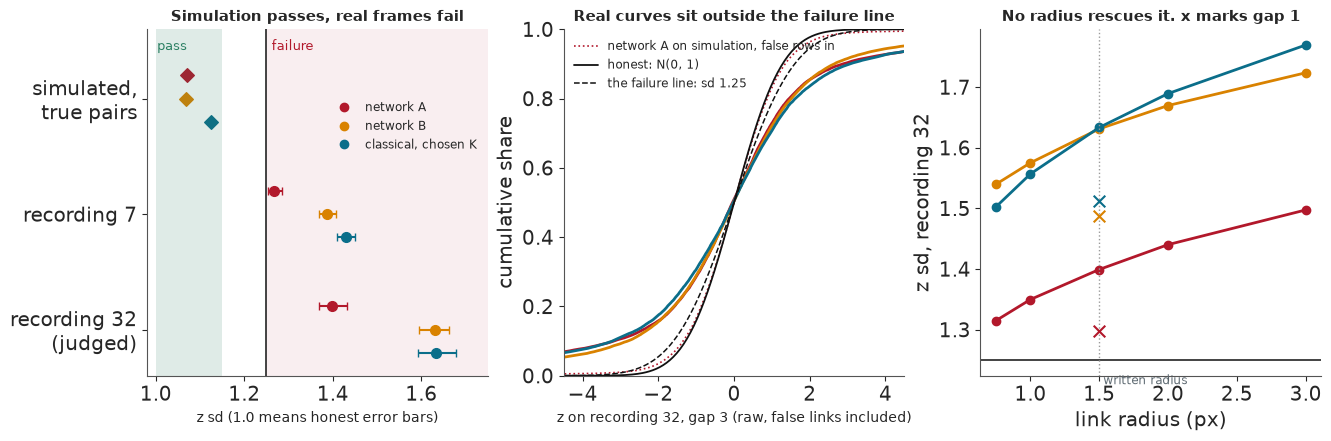

In [12]:
verdicts = paired["verdicts"]
rows = []
for key, title in (("r32", "recording 32, judged"), ("r7", "recording 7"), ("r32_line", "recording 32, line calibration"),
                   ("r7_line", "recording 7, line calibration")):
    rows.append({"where": title, "A": verdicts[f"{key}_a"]["z"], "A 95% half": verdicts[f"{key}_a"]["halfwidth95"],
                 "A 1 se": verdicts[f"{key}_a"]["one_se"], "B": verdicts[f"{key}_b"]["z"],
                 "B 95% half": verdicts[f"{key}_b"]["halfwidth95"], "B 1 se": verdicts[f"{key}_b"]["one_se"],
                 "classical": verdicts[f"{key}_a"]["classical_z"], "K = 1": paired["rows"][key]["K1"]["gap3_R1.5"]["matched_chosen"]["z_sd"],
                 "K = 1, own basis": verdicts[f"{key}_a"]["k1_z"],
                 "absolute": f"{verdicts[f'{key}_a']['absolute']}, {verdicts[f'{key}_b']['absolute']}",
                 "relative": verdicts[f"{key}_a"]["relative"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
sim = paired["rows"]["simulated"]
print("\nSimulated baseline, gap 3, unweighted, whole field:",
      ", ".join(f"{NAME[m]} {sim[m]['gap3_R1.5']['unweighted']['z_sd']:.2f}" for m in ("a", "b", "chosen", "K1")))
print("It tests the method. It says nothing of the microscope.")
truth = posthoc["sim"]
print("Post-hoc, pairs with both ends on a true emitter: " + ", ".join(f"{NAME[m]} {truth[m]['z_both_true']:.2f}" for m in ("a", "b", "chosen", "K1")))
print("Share of rows within 2 px of a true emitter: " + ", ".join(f"{NAME[m]} {truth[m]['precision']:.2f}" for m in ("a", "b", "chosen", "K1"))
      + f". A's gap-3 pairs: {truth['a']['pairs']:,}, of which {truth['a']['pairs_neither']:,} join two false rows, yet the mixture calls {truth['a']['mixture_true_share']:.0%} true")
print(f"Network B at gap 1 on simulation: z {sim['b']['gap1_R1.5']['unweighted']['z_sd']:.2f}, where its 3-frame input shares pixels")

extra = posthoc["real"]
print("\nPost-hoc, the same links read other ways. Gated values above are unchanged.")
rows = []
for rec in ("r32", "r7"):
    common, floor = extra[rec]["common"], extra[rec]["floor"]
    for m in ("chosen", "K1", "a", "b"):
        row = paired["rows"][rec][m]["gap3_R1.5"]
        rows.append({"recording": RECS[rec], "method": NAME[m], "own pairs": row["pairs"], "matched z": row["matched_chosen"]["z_sd"], "matched to K = 1": row["matched_K1"]["z_sd"],
                     "unweighted z": row["unweighted"]["z_sd"], "unw. upper": row["unweighted"]["z_sd_hi"], "common z": common["z"][m], "common scatter nm": common["scatter_nm"][m],
                     "z tight / mid / wide sd": " / ".join(f"{v:.2f}" for v in extra[rec]["sd_tertiles"][m]), "residual scale": floor[m]["c"], "floor nm per frame": floor[m]["floor_nm"] / np.sqrt(2)})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"Common pairs: {extra['r32']['common']['pairs']:,} on recording 32, {extra['r7']['common']['pairs']:,} on recording 7. Scatter by gap 1 / 3 / 10, K = 1, recording 32: "
      + " / ".join(f"{extra['r32']['by_gap_scatter_nm']['K1'][g]:.1f}" for g in ("1", "3", "10")) + " nm")

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.3), layout="constrained")
ax = axes[0]
place = {"sim": 3, "r7": 2, "r32": 1}
offsets = {"a": 0.2, "b": 0.0, "chosen": -0.2}
for m, shift in offsets.items():
    judged, other = paired["rows"]["r32"][m]["gap3_R1.5"], paired["rows"]["r7"][m]["gap3_R1.5"]
    for y, row in ((place["r32"], judged), (place["r7"], other)):
        q = row["matched_chosen"]
        ax.errorbar(q["z_sd"], y + shift, xerr=[[q["z_sd"] - q["z_sd_lo"]], [q["z_sd_hi"] - q["z_sd"]]], fmt="o", ms=7,
                    color=COLOUR[m], capsize=3)
    ax.scatter(posthoc["sim"][m]["z_both_true"], place["sim"] + shift, s=48, marker="D", color=COLOUR[m])
ax.axvspan(1.0, 1.15, color="#2a7f62", alpha=0.15, lw=0)
ax.axvspan(1.25, 1.75, color=NET_A, alpha=0.07, lw=0)
ax.axvline(1.25, color=LINE_COL, lw=1.1)
ax.text(1.003, 3.42, "pass", fontsize=9, color="#2a7f62")
ax.text(1.262, 3.42, "failure", fontsize=9, color=NET_A)
ax.set_yticks([1, 2, 3], ["recording 32\n(judged)", "recording 7", "simulated,\ntrue pairs"])
ax.set(xlim=(0.98, 1.75), ylim=(0.6, 3.6))
ax.set_xlabel("z sd (1.0 means honest error bars)", fontsize=10)
ax.set_title("Simulation passes, real frames fail", fontsize=11)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=COLOUR[m], label=NAME[m]) for m in offsets], loc="center right",
          bbox_to_anchor=(1.0, 0.72), fontsize=8.5)

ax = axes[1]
q = pack["z_quantiles"]
grid_z = np.linspace(-4.5, 4.5, 200)
for m in ("a", "b", "chosen"):
    ax.plot(pack[f"r32_z_{m}"], q, color=COLOUR[m], lw=2)
ax.plot(pack["sim_z_a"], q, color=NET_A, lw=1.2, ls=":", label="network A on simulation, false rows in")
ax.plot(grid_z, stats.norm.cdf(grid_z), color=LINE_COL, lw=1.3, label="honest: N(0, 1)")
ax.plot(grid_z, stats.norm.cdf(grid_z, scale=1.25), color=LINE_COL, lw=1.1, ls="--", label="the failure line: sd 1.25")
ax.set(xlim=(-4.5, 4.5), ylim=(0, 1), ylabel="cumulative share")
ax.set_xlabel("z on recording 32, gap 3 (raw, false links included)", fontsize=10)
ax.set_title("Real curves sit outside the failure line", fontsize=11)
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[2]
radii = (0.75, 1.0, 1.5, 2.0, 3.0)
for m in ("a", "b", "chosen"):
    z = [paired["rows"]["r32"][m][f"gap3_R{r}"]["matched_chosen"]["z_sd"] for r in radii]
    ax.plot(radii, z, "o-", color=COLOUR[m], lw=2)
    gap1 = paired["rows"]["r32"][m]["gap1_R1.5"]["matched_chosen"]["z_sd"]
    ax.scatter(1.5, gap1, marker="x", s=70, color=COLOUR[m], zorder=4)
ax.axhline(1.25, color=LINE_COL, lw=1.1)
ax.axvline(1.5, color=MUTED, lw=1, ls=":")
ax.text(1.53, 1.21, "written radius", fontsize=8.5, color=SINGLE)
ax.set(xlabel="link radius (px)", ylabel="z sd, recording 32")
ax.set_title("No radius rescues it. x marks gap 1", fontsize=11);

**Both networks fail.** On recording 32 the sd of $z$ is 1.40 for A and 1.63 for B, with 95% half-widths
of about 0.03. On recording 7 both are over the line too, A only just (1.27), and the line calibration
does not rescue either. On simulation the test works: on pairs with both ends on a true emitter, $z$ is
1.06-1.13 for every method, so what differs on real frames is the microscope. Raw simulated pairs flatter
A, though: half of its rows there match no emitter, and 34,028 of its 43,555 pairs join two false rows
stuck at fixed sites, which agree with each other and fool the mixture.

**"No worse than classical" is true, and weak.** The classical chosen-$K$ fit also scores 1.63 on
recording 32. But each method keeps its own pairs, matched on brightness only. On literally the same 4,337
pairs, which we looked at after the run, $z$ is 1.55 for chosen $K$, 1.51 for $K = 1$, 1.44 for A and 1.76
for B, and A's scatter equals $K = 1$'s at 12.0 nm. **The classical fitter's error bars are too small as
well**; no method here has honest error bars on real frames.

**A $z$ of 1.4 does not mean the scatter is 1.4 times the sd.** In every method $z$ falls as the sd
widens: on recording 32, $K = 1$ goes 1.99, 1.41, 1.29 from the tightest third of pairs to the widest.
That is the signature of a floor. A fit with a floor and a scale gives about 4-6 nm per frame on top of
each sd in all four methods, which looks like movement of the sample or stage rather than any localiser.
A residual scale of 1.1-1.5 remains that we cannot explain. The practical advice: add a floor of a few
nanometres before you scale any sd.

**B got worse than A.** The fix took $z$ from 1.40 to 1.63, and B's scatter on common pairs rose 20% over
A's. On recording 32 no link radius rescues either network, because real displacements have heavier tails
than the mixture allows; on recording 7, A dips under 1.25 at radii of 0.75 and 1 px. A gap of 1 looks
better for the networks (1.30 and 1.49), the shared-pixel trap the gap of 3 avoids. Classical also falls
at gap 1, to 1.51, though its fits are independent, so shared pixels are not the whole story.

### Check 2: the companion halo

E58 found faint companions 301-462 nm from bright spots: fitters explaining the PSF's wings with extra
emitters. Do networks invent the same ring? We call it a failure if the density of faint detections in
that ring is more than twice the far-field density.

halo ratio, line 2       rec 32    rec 7  rec 32 shifted  rec 7 shifted
network A                  5.39     5.17            1.27           1.13
network B                  2.69     1.95            0.98           1.02
classical, chosen K       39.26    37.40            1.65           1.33
classical, K = 1           0.01     0.00            1.28           1.05
Shifted, post-hoc: faint rows taken from frames 200-800 away, so nothing in them can belong to the bright spot


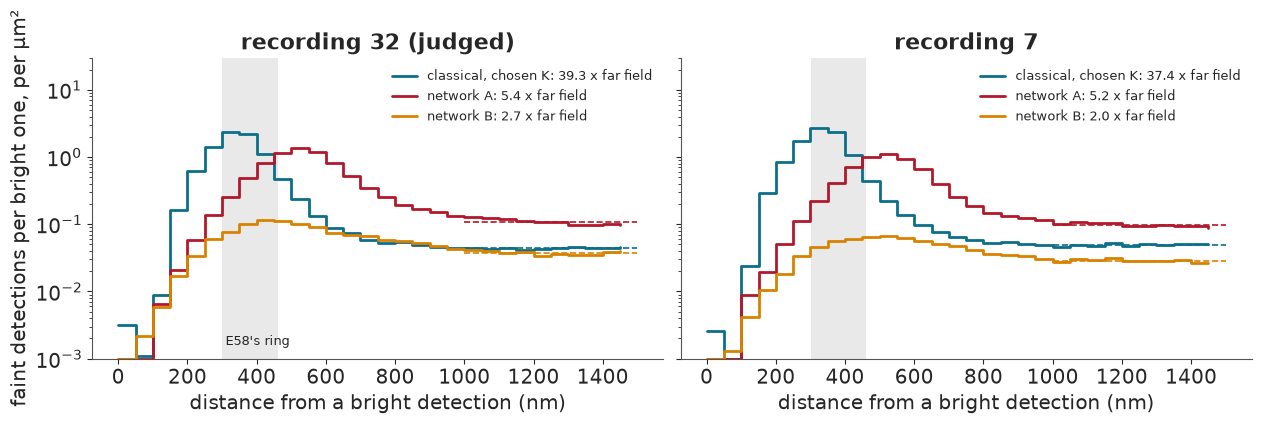

In [13]:
print(f"{'halo ratio, line 2':22}{'rec 32':>9}{'rec 7':>9}{'rec 32 shifted':>16}{'rec 7 shifted':>15}")
for m in ("a", "b", "chosen"):
    print(f"{NAME[m]:22}{halo['r32'][m]['ratio']:>9.2f}{halo['r7'][m]['ratio']:>9.2f}{posthoc['halo']['r32'][m]['shifted']:>16.2f}{posthoc['halo']['r7'][m]['shifted']:>15.2f}")
print(f"{NAME['K1']:22}{posthoc['halo']['r32']['K1']['ratio']:>9.2f}{posthoc['halo']['r7']['K1']['ratio']:>9.2f}{posthoc['halo']['r32']['K1']['shifted']:>16.2f}{posthoc['halo']['r7']['K1']['shifted']:>15.2f}")
print("Shifted, post-hoc: faint rows taken from frames 200-800 away, so nothing in them can belong to the bright spot")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True, layout="constrained")
for ax, rec in zip(axes, ("r32", "r7")):
    for m in ("chosen", "a", "b"):
        row = halo[rec][m]
        edges = np.array(row["edges_nm"])
        ax.step(edges[:-1], np.maximum(row["density"], 1e-3), where="post", color=COLOUR[m], lw=2,
                label=f"{NAME[m]}: {row['ratio']:.1f} x far field")
        ax.hlines(row["density_far"], 1000, 1500, color=COLOUR[m], lw=1.2, ls="--")
    ax.axvspan(301, 462, color="#555555", alpha=0.13, lw=0)
    ax.set_yscale("log")
    ax.set(xlabel="distance from a bright detection (nm)", ylim=(1e-3, 30), title=RECS[rec] + (" (judged)" if rec == "r32" else ""))
    ax.legend(loc="upper right", fontsize=9)
axes[0].text(310, 0.0016, "E58's ring", fontsize=9)
axes[0].set_ylabel("faint detections per bright one, per µm²");

**A fails on both recordings at about 5 times the far field.** B halves that: 2.7 on recording 32, still a
failure, and 1.95 on recording 7, a pass. Of all B's changes this is the one that did what it was built
for, though its simulator changed several things at once. Taking the faint rows from frames 200-800 away
gives 0.98-1.27, so the clustering of the sample does not inflate the ratio. There is no fair classical
comparison: chosen $K$ reads 37-39 because rows from a fit with $K \ge 2$ sit in one blob by construction,
and $K = 1$ reads 0.01 because it is blind inside a blob. Note too that A's excess peaks near 500 nm,
outside E58's ring, so 5.4 understates it.

### Check 3: the population replicate, and a lineup

Simulate fresh frames from each network's fitted *population* (density, brightness, PSF, background),
never from the frames' own fitted emitters, which would look right by construction, and compare the blobs
with the real ones. This check has no threshold: it describes, it does not judge. First, try
the lineup (Buja et al. 2009): **one panel of nine is real.**

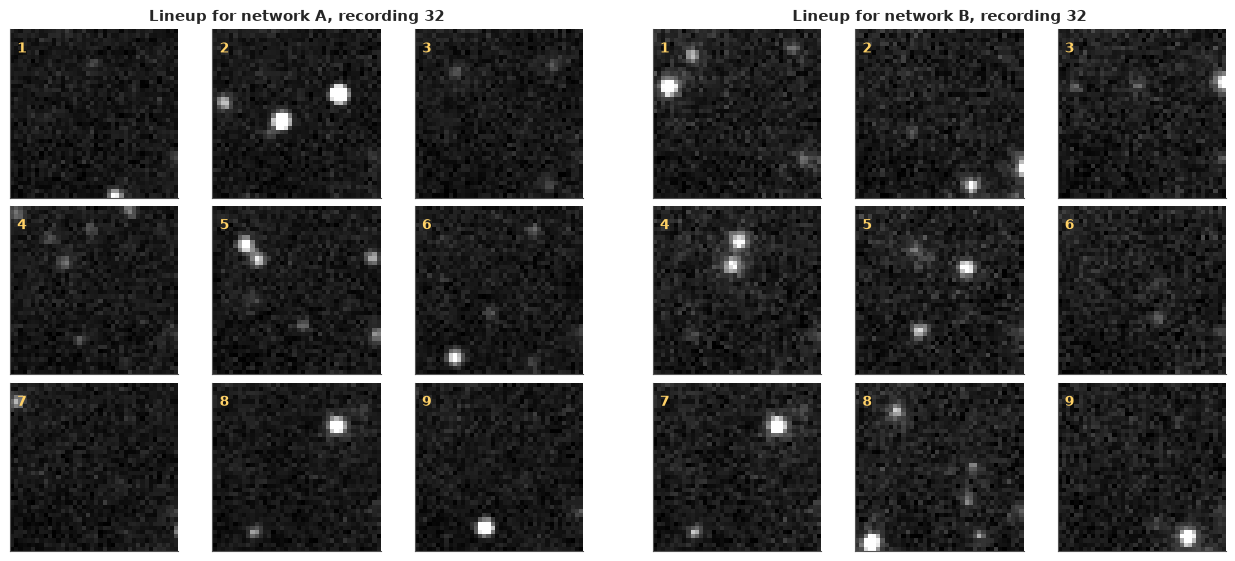

In [14]:
fig, axes = plt.subplots(3, 7, figsize=(12.5, 5.5), width_ratios=[1, 1, 1, 0.14, 1, 1, 1], layout="constrained")
for col in range(3):
    axes[col, 3].axis("off")
for offset, net in zip((0, 4), ("a", "b")):
    panels = pack[f"lineup_r32_{net}"]
    low, high = np.percentile(panels, [1, 99.7])
    for i in range(9):
        ax = axes[i // 3, offset + i % 3]
        ax.imshow(panels[i], cmap="gray", vmin=low, vmax=high, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.text(1.2, 5, str(i + 1), color="#ffd166", fontsize=10, weight="bold")
    axes[0, offset + 1].set_title(f"Lineup for {NAME[net]}, recording 32", fontsize=11);

The answer is in the next cell. Decide first: which panel is real in each lineup? Both hold the same real
frame.

network A: the real panel is number 8
network B: the real panel is number 7

   recording   network  KS area  KS peak  blobs real  blobs replicate median area real, rep median peak real, rep
 recording 7 network A   0.2079   0.1428        7814            17509          (24.0, 14.0)          (86.0, 60.0)
 recording 7 network B   0.1476   0.0942        7814             9810          (24.0, 25.0)          (86.0, 94.0)
recording 32 network A   0.2776   0.1816        5290            12138          (28.0, 14.0)         (101.5, 65.0)
recording 32 network B   0.1293   0.0958        5290             8080          (28.0, 20.0)         (101.5, 77.0)


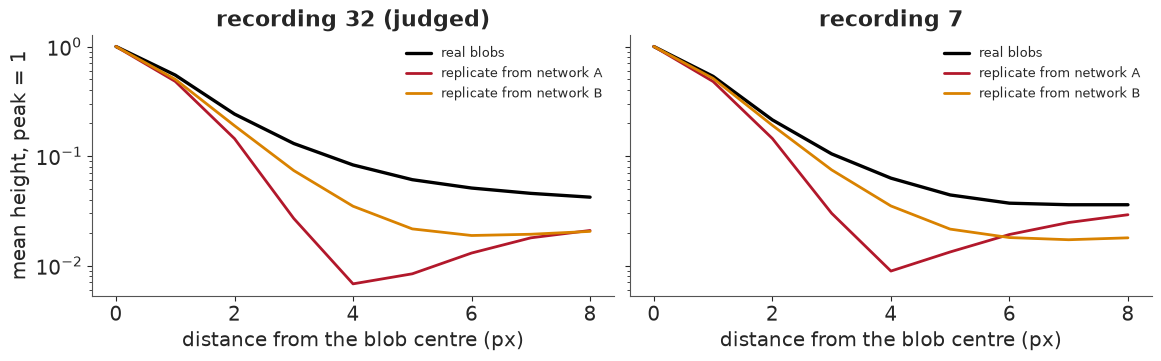

In [15]:
for net in ("a", "b"):
    print(f"{NAME[net]}: the real panel is number {int(pack[f'lineup_r32_{net}_real']) + 1}")
print()
rows = []
for rec in RECS:
    for net in ("a", "b"):
        r = replicate[rec][net]
        rows.append({"recording": RECS[rec], "network": NAME[net], "KS area": r["ks_area"], "KS peak": r["ks_peak"],
                     "blobs real": r["blobs_real"], "blobs replicate": r["blobs_replicate"],
                     "median area real, rep": tuple(r["median_area"]), "median peak real, rep": tuple(r["median_peak"])})
print(pd.DataFrame(rows).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), sharey=True, layout="constrained")
for ax, rec in zip(axes, ("r32", "r7")):
    real = np.array(replicate[rec]["a"]["profile_real"])
    px = np.arange(len(real))
    ax.plot(px, np.maximum(real, 1e-4), color="k", lw=2.4, label="real blobs")
    for net in ("a", "b"):
        ax.plot(px, np.maximum(replicate[rec][net]["profile_replicate"], 1e-4), color=COLOUR[net], lw=2, label=f"replicate from {NAME[net]}")
    ax.set_yscale("log")
    ax.set(xlabel="distance from the blob centre (px)", title=RECS[rec] + (" (judged)" if rec == "r32" else ""))
    ax.legend(fontsize=9)
axes[0].set_ylabel("mean height, peak = 1");

A's population gives far too many small blobs: on recording 32, 12,138 against 5,290 real ones, with a
median area of 14 px against 28. B is closer on both Kolmogorov-Smirnov distances (0.13 against 0.28 for
area), but its blobs are still too many, too small and too faint. **The simple simulator fails a check you
can run without labels, and the empirical one improves on it without reaching the data.**

### Check 4: the NUTS audit

The classical sds come from a Laplace approximation. Does it hold? We ran NUTS on E58's spot model for 200
spots of recording 7, half with $K = 1$ and half with $K = 2$, and compared the sds. NUTS shares the
forward model with the fit, so this checks the approximation, not the model. We want the median ratio of
NUTS to Laplace sd within 0.8-1.25, with every spot at r_hat 1.01 or below and no divergences.

Median NUTS / Laplace sd, line 0.8-1.25: 1.54 (K = 1 1.04, K = 2 2.64). Converged only, descriptive: 1.06 (K = 1 1.03, K = 2 1.48)
P7's lines on 200 spots: max r_hat 3.11 (line 1.01), 87 spots over (26 K = 1, 61 K = 2), 30,458 divergences (line 0), minimum ESS 4.6
Against the networks: matched 212 (A) and 171 (B) of 300 positions, median distance 11.7 and 13.3 nm, median NUTS sd over network sd 1.26 and 1.45, all spots

Post-hoc rerun, same posterior with the start on the spot, same seeds and spots, empty compile cache then warm:
  empty  ratio 1.11 (K = 1 1.02, K = 2 1.91; K = 2 converged 1.48); over r_hat 1.01: K = 1 0, K = 2 45; divergences 368 (K = 1 9); chain gap on the unconverged, median 0.6 nats
  warm   ratio 1.14 (K = 1 1.02, K = 2 1.85; K = 2 converged 1.55); over r_hat 1.01: K = 1 0, K = 2 35; divergences 229 (K = 1 8); chain gap on the unconverged, median 0.6 nats
  K = 1: the fitter's row sits within 0.5 px of the NUTS mean on 99 of 100 spots, photon ratio 1.00
Stored for

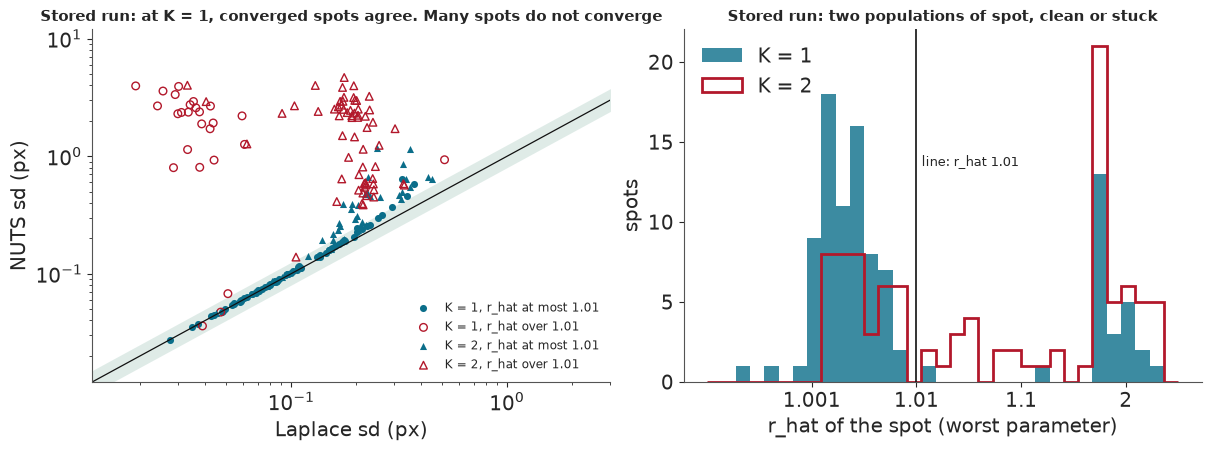

In [16]:
K, rhat, nuts_sd, laplace_sd = pack["audit_K"], pack["audit_rhat"], pack["audit_nuts_sd_px"], pack["audit_laplace_sd_px"]
good = rhat <= 1.01
print(f"Median NUTS / Laplace sd, line 0.8-1.25: {audit['median_sd_ratio']['all']:.2f} (K = 1 {audit['median_sd_ratio']['K1']:.2f}, "
      f"K = 2 {audit['median_sd_ratio']['K2']:.2f}). Converged only, descriptive: {audit['median_sd_ratio']['converged']:.2f} "
      f"(K = 1 {audit['median_sd_ratio']['K1_converged']:.2f}, K = 2 {audit['median_sd_ratio']['K2_converged']:.2f})")
print(f"P7's lines on 200 spots: max r_hat {audit['max_rhat']:.2f} (line 1.01), {audit['over_1_01']['K1'] + audit['over_1_01']['K2']} spots over "
      f"({audit['over_1_01']['K1']} K = 1, {audit['over_1_01']['K2']} K = 2), {audit['divergences']:,} divergences (line 0), minimum ESS {audit['min_ess']:.1f}")
print(f"Against the networks: matched {audit['nets']['a']['matched']} (A) and {audit['nets']['b']['matched']} (B) of "
      f"{audit['nets']['a']['of']} positions, median distance {audit['nets']['a']['median_distance_nm']:.1f} and "
      f"{audit['nets']['b']['median_distance_nm']:.1f} nm, median NUTS sd over network sd "
      f"{audit['nets']['a']['median_nuts_over_net_sd']:.2f} and {audit['nets']['b']['median_nuts_over_net_sd']:.2f}, all spots")
cold, warm, stuck_chains = posthoc["nuts_cold"], posthoc["nuts_warm"], posthoc["stuck"]
print("\nPost-hoc rerun, same posterior with the start on the spot, same seeds and spots, empty compile cache then warm:")
for tag, r in (("empty", cold), ("warm", warm)):
    print(f"  {tag:6} ratio {r['median_sd_ratio']['all']:.2f} (K = 1 {r['median_sd_ratio']['K1']:.2f}, K = 2 {r['median_sd_ratio']['K2']:.2f}; K = 2 converged "
          f"{r['median_sd_ratio']['K2_converged']:.2f}); over r_hat 1.01: K = 1 {r['over_1_01']['K1']}, K = 2 {r['over_1_01']['K2']}; "
          f"divergences {r['divergences']['all']:,} (K = 1 {r['divergences']['K1']}); chain gap on the unconverged, median {r['chain_gap_unconverged']['median']:.1f} nats")
print(f"  K = 1: the fitter's row sits within 0.5 px of the NUTS mean on {cold['K1_fit']['within_half_px']} of {cold['K1_fit']['of']} spots, photon ratio {cold['K1_fit']['median_N_ratio']:.2f}")
print(f"Stored form rerun on the 87 stuck spots: a gap of 20 nats or more on {stuck_chains['gap_20']['K1']} of {stuck_chains['of']['K1']} K = 1 and "
      f"{stuck_chains['gap_20']['K2']} of {stuck_chains['of']['K2']} K = 2; each stuck spot's best chain gives a ratio of {stuck_chains['best_chain_sd_ratio']['all']:.2f} "
      f"(K = 1 {stuck_chains['best_chain_sd_ratio']['K1']:.2f}, K = 2 {stuck_chains['best_chain_sd_ratio']['K2']:.2f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
ax = axes[0]
span = np.array([0.008, 12])
ax.fill_between(span, span * 0.8, span * 1.25, color="#2a7f62", alpha=0.15, lw=0)
ax.plot(span, span, color=LINE_COL, lw=0.9)
for k, marker in ((1, "o"), (2, "^")):
    keep = K == k
    ax.scatter(laplace_sd[keep & good], nuts_sd[keep & good], s=26, marker=marker, color=CLASSICAL, lw=0, label=f"K = {k}, r_hat at most 1.01")
    ax.scatter(laplace_sd[keep & ~good], nuts_sd[keep & ~good], s=30, marker=marker, facecolor="none", edgecolor=NET_A, label=f"K = {k}, r_hat over 1.01")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(xlim=(0.012, 3), ylim=(0.012, 12), xlabel="Laplace sd (px)", ylabel="NUTS sd (px)")
ax.set_title("Stored run: at K = 1, converged spots agree. Many spots do not converge", fontsize=11)
ax.legend(fontsize=8.5, loc="lower right")
ax = axes[1]
ax.hist(np.log10(rhat[K == 1] - 1), bins=np.linspace(-4, 0.5, 34), color=CLASSICAL, alpha=0.8, label="K = 1")
ax.hist(np.log10(rhat[K == 2] - 1), bins=np.linspace(-4, 0.5, 34), histtype="step", color=NET_A, lw=2, label="K = 2")
ax.axvline(-2, color=LINE_COL, lw=1.2)
ax.text(-1.95, 13.5, "line: r_hat 1.01", fontsize=9)
ax.set_xticks([-3, -2, -1, 0], ["1.001", "1.01", "1.1", "2"])
ax.set(xlabel="r_hat of the spot (worst parameter)", ylabel="spots")
ax.set_title("Stored run: two populations of spot, clean or stuck", fontsize=11)
ax.legend();

As stored, the audit fails: the median ratio is 1.54, 87 of 200 spots miss r_hat 1.01, and there are
30,458 divergences. On the $K = 1$ spots that converge, NUTS and Laplace agree (1.03), so the excess in
check 1 is not a Laplace problem at $K = 1$ but lies in the forward model both share. At $K = 2$ even
converged spots sit at 1.48.

**Most of that failure was a bug in our audit.** The chains never started on the spot. In nutpie 0.16.11,
`with_data` swaps the data inside the log density, but the starting point keeps the compile-time
placeholders, here the corner of the patch. After finding this we reran the same posterior written
non-centred, so that the start follows the data (section 8 shows how). The ratio becomes 1.11-1.14, inside
0.8-1.25, all 100 $K = 1$ spots reach r_hat 1.01, and the fitter's position sits within 0.5 px of the NUTS
mean for 99 of them, with a median photon ratio of 1.00. **Laplace looks sound at $K = 1$ on recording 7**,
though 8-9 divergences remain across the 100 spots. Section 9's table keeps the original audit.

**$K = 2$ is the open problem.** There 35-45 spots stay above r_hat 1.01 even from a good start, and the
ratio is about 1.9 overall and 1.5 on spots that converge. Their chains sit a median 0.6 nats apart, so
most are slow mixing or competing configurations, though a few are still trapped. This rests on one
reparameterisation, run after the stored audit.

## 8 · A live audit in PyMC

This part runs on your machine. The summary keeps the pixels of four spots chosen by a rule: for $K = 1$
and $K = 2$, the spot with the worst stored r_hat and the first clean one. The model is E58's spot model.
`pm.Data` plus `nutpie.compile_pymc_model(...).with_data(...)` means each $K$ compiles once and every spot
reuses it. With two emitters, draws are sorted on $x$ before r_hat, since label switching is not a
sampling failure.

We run the stored, centred form on the worst $K = 1$ spot, keeping the warm-up to see where the chains
start, then the same posterior written non-centred, $x = c_x + 2 r_x$ with $r_x \sim N(0, 1)$, on all
four. **If you use `with_data`, check that your starting point does not depend on the data you swapped
in.**

Stored form, worst K = 1 spot, centre 5.5, 4.5. First warmup draw of each chain:
  x  -0.8   0.4  -1.1  -0.4
  y  -0.8  -0.7   0.3   0.5
  r_hat 3.012 (stored 3.012), 400 divergences



Compiled 3 models in 44 s. The start on the spot, all four spots:
 K  stored_r_hat  live_r_hat  live_ess  seconds  divergences
 1         3.012       1.002  2625.668    0.194            0
 1         1.001       1.002  2179.442    0.201            0
 2         3.113       1.003  2909.614    0.238            0
 2         1.002       1.003  1289.121    0.324            0
Log density gap, best chain minus worst: 0, 0, 0, 0

Each chain, first emitter (sorted on x when K = 2):
  K = 1 worst, stored form
    chain 0: x   5.6, sd of x 2.19, photons     830, background  159, mean logp  -2400.8
    chain 1: x   5.4, sd of x 0.07, photons   5,970, background  112, mean logp   -435.1
    chain 2: x   5.1, sd of x 0.06, photons     162, background  158, mean logp  -2387.1
    chain 3: x   9.2, sd of x 4.00, photons     338, background  159, mean logp  -2399.5
  K = 1 worst, start on the spot
    chain 0: x   5.4, sd of x 0.03, photons   6,007, background  110, mean logp   -429.8
    chain 1: x   5.

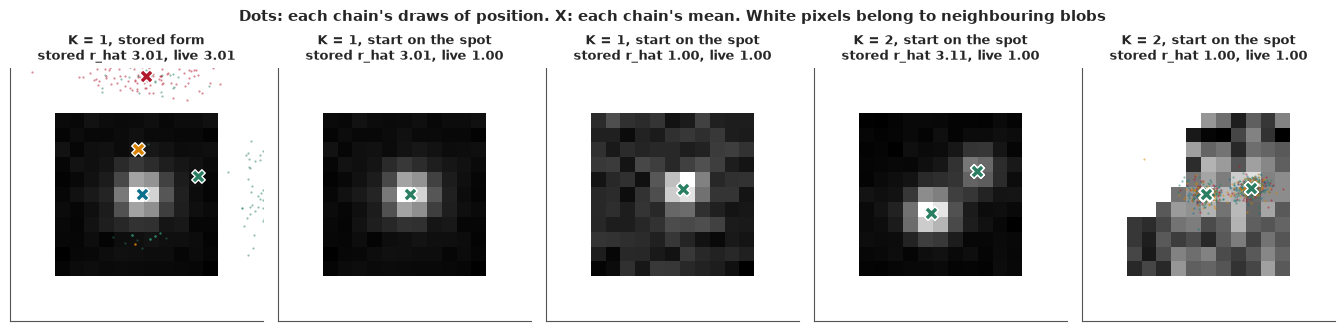

In [17]:
PIX = np.arange(PATCH)
SQ2 = np.sqrt(2.0)


def spot_model(K, centred=False):
    """E58's spot model on one masked 11 x 11 patch: the same posterior as the Laplace fit it audits, in either form."""

    def pixel(u, s):
        return 0.5 * (pt.erf((PIX + 0.5 - u[..., None]) / (SQ2 * s)) - pt.erf((PIX - 0.5 - u[..., None]) / (SQ2 * s)))

    with pm.Model() as model:
        z = pm.Data("z", np.zeros(PATCH * PATCH))
        w = pm.Data("w", np.ones(PATCH * PATCH))
        cx, cy = pm.Data("cx", np.zeros(K)), pm.Data("cy", np.zeros(K))
        lb = pm.Data("lb", 5.0)
        # Centred, the stored form: its start keeps the placeholders above, whatever with_data supplies.
        # Non-centred: rb, rx and ry start at 0, so x and y start on the spot.
        logb = pm.Normal("logb", lb, 0.5) if centred else pm.Deterministic("logb", lb + 0.5 * pm.Normal("rb", 0.0, 1.0))
        logs = pm.Normal("logs", 0.0, 0.2)
        x = pm.Normal("x", cx, 2.0, shape=K) if centred else pm.Deterministic("x", cx + 2.0 * pm.Normal("rx", 0.0, 1.0, shape=K))
        y = pm.Normal("y", cy, 2.0, shape=K) if centred else pm.Deterministic("y", cy + 2.0 * pm.Normal("ry", 0.0, 1.0, shape=K))
        logN = pm.Normal("logN", np.log(1500.0), 1.0, shape=K)
        s = pt.exp(logs)
        image = pt.sum(pt.exp(logN)[:, None, None] * pixel(y, s)[:, :, None] * pixel(x, s)[:, None, :], axis=0)
        mu = (pt.exp(logb) + image).ravel() / 2
        pm.Potential("ll", pt.sum(w * (z * pt.log(mu) - mu - pt.gammaln(z + 1))))
    return model


def audit_spot(compiled_model, i, **options):
    """One spot, 4 chains, the stored seed and settings; the same summary for either form."""
    spot, cen = pack["spot_id"][i], pack["spot_cen"][i]
    k = int(K[spot])
    model = compiled_model.with_data(z=pack["spot_Z"][i].ravel().astype(float), w=pack["spot_W"][i].ravel().astype(float),
                                     cx=np.full(k, float(cen[0])), cy=np.full(k, float(cen[1])), lb=float(pack["spot_logb"][i]))
    t0 = time.perf_counter()
    trace = nutpie.sample(model, chains=4, tune=1000, draws=1000, cores=min(4, CORES), seed=int(pack["spot_seed"][i]), progress_bar=False, **options)
    post = trace.posterior
    x, y, logN = post["x"].values, post["y"].values, post["logN"].values
    if k == 2:
        order = np.argsort(x, axis=-1)
        x, y, logN = (np.take_along_axis(v, order, -1) for v in (x, y, logN))
    arrays = dict(x=x, y=y, logN=logN, logb=post["logb"].values[..., None], logs=post["logs"].values[..., None])
    r_hat = max(float(az.rhat(v[..., j])) for v in arrays.values() for j in range(v.shape[-1]))
    ess = min(float(az.ess(v[..., j])) for v in arrays.values() for j in range(v.shape[-1]))
    return trace, dict(K=k, stored_r_hat=float(rhat[spot]), live_r_hat=r_hat, live_ess=ess, seconds=time.perf_counter() - t0,
                       divergences=int(trace.sample_stats["diverging"].sum()), x=x, y=y, logN=logN, logb=arrays["logb"],
                       logp=trace.sample_stats["logp"].mean("draw").values)


t0 = time.perf_counter()
stored_form = nutpie.compile_pymc_model(spot_model(1, centred=True))
compiled = {k: nutpie.compile_pymc_model(spot_model(k)) for k in (1, 2)}
compile_s = time.perf_counter() - t0
worst_k1 = int(np.argmax(rhat[pack["spot_id"]] * (K[pack["spot_id"]] == 1)))
trace_stored, as_stored = audit_spot(stored_form, worst_k1, save_warmup=True)
first = trace_stored.warmup_posterior
print(f"Stored form, worst K = 1 spot, centre {pack['spot_cen'][worst_k1][0]:.1f}, {pack['spot_cen'][worst_k1][1]:.1f}. First warmup draw of each chain:")
print("  x " + " ".join(f"{v:5.1f}" for v in first["x"].values[:, 0, 0]) + "\n  y " + " ".join(f"{v:5.1f}" for v in first["y"].values[:, 0, 0]))
print(f"  r_hat {as_stored['live_r_hat']:.3f} (stored {as_stored['stored_r_hat']:.3f}), {as_stored['divergences']:,} divergences\n")
live = [audit_spot(compiled[int(K[spot])], i)[1] for i, spot in enumerate(pack["spot_id"])]
print(f"Compiled 3 models in {compile_s:.0f} s. The start on the spot, all four spots:")
print(pd.DataFrame([{k: v for k, v in row.items() if not isinstance(v, np.ndarray)} for row in live]).round(3).to_string(index=False))
print(f"Log density gap, best chain minus worst: " + ", ".join(f"{row['logp'].max() - row['logp'].min():,.0f}" for row in live))
print("\nEach chain, first emitter (sorted on x when K = 2):")
for row, name in zip([as_stored] + live, ("K = 1 worst, stored form", "K = 1 worst, start on the spot", "K = 1 clean", "K = 2 worst", "K = 2 clean")):
    print(f"  {name}")
    for c in range(4):
        print(f"    chain {c}: x {row['x'][c, :, 0].mean():5.1f}, sd of x {row['x'][c, :, 0].std():.2f}, photons "
              f"{np.exp(row['logN'][c, :, 0].mean()):7,.0f}, background {np.exp(row['logb'][c].mean()):4.0f}, mean logp {row['logp'][c]:8.1f}")

fig, axes = plt.subplots(1, 5, figsize=(13.4, 3.2), layout="constrained")
palette = ("#b2182b", "#0b6e8a", "#d98200", "#2a7f62")
panels = [(worst_k1, as_stored, "K = 1, stored form")] + [(i, row, f"K = {row['K']}, start on the spot") for i, row in enumerate(live)]
for ax, (i, row, title) in zip(axes, panels):
    image = np.ma.masked_where(pack["spot_W"][i] == 0, pack["spot_Z"][i])
    ax.imshow(image, cmap="gray", origin="upper", interpolation="nearest")
    for c in range(4):
        ax.scatter(row["x"][c, ::10].ravel(), row["y"][c, ::10].ravel(), s=2.5, color=palette[c], alpha=0.5, lw=0)
    for c in range(4):
        ax.scatter(row["x"][c].mean(0), row["y"][c].mean(0), s=95, marker="X", color=palette[c], edgecolor="w", lw=1, zorder=4)
    ax.set(xlim=(-3.5, PATCH + 2.5), ylim=(PATCH + 2.5, -3.5), xticks=[], yticks=[])
    ax.set_title(f"{title}\nstored r_hat {row['stored_r_hat']:.2f}, live {row['live_r_hat']:.2f}", fontsize=9)
fig.suptitle("Dots: each chain's draws of position. X: each chain's mean. White pixels belong to neighbouring blobs", fontsize=11);

**The start explains the $K = 1$ failure.** In the stored form every chain starts within about a pixel of
$(0, 0)$, while the spot is at $(5.5, 4.5)$, and r_hat is 3.01 as stored. Only chain 1 reaches the spot:
about 6,000 photons on a background of 112. The other three hold 160-830 photons on a raised background
near 159, almost 2,000 nats lower in log density, and in two of them the emitter roams with an sd of 2-4
px, the width of the prior. Start on the spot, with the same posterior and seed, and all four chains agree
on about 6,000 photons at r_hat 1.002, with no divergences. The worst $K = 2$ spot also converges (r_hat
1.003), though section 7 showed not every $K = 2$ spot does.

A state 2,000 nats below another has a relative posterior weight of about $e^{-2000}$, so it is no rival
explanation of the pixels. The stored r_hat reports a bad start and a stalled sampler, not a wider
posterior.

One loose end: the stored $K = 2$ numbers depend on PyTensor's compile cache (r_hat 3.11 warm and 4.42
empty for the worst spot), for reasons we have not found. Across the audit this moves the ratio from 1.54
to 1.52, so no conclusion changes.

## 9 · All the checks together

The table collects every check with a threshold: the small pilot runs (P2-P8) and the four checks of
section 7.

In [18]:
p2 = store.load_json("p2_classical_r7")
audit_stage = next(row["seconds"] for row in store.stages() if row["stage"] == "audit_nuts")
p5p, p6, p7, p8 = p5["5,000 steps (P5, NO-GO)"], store.load_json("p6_p5"), store.load_json("p7_audit"), store.load_json("p8_resume")
p8_same = store.load_json("train_p8refd")["last_loss"] == store.load_json("train_p8kd")["last_loss"]
p8_slow, p8_fast = store.load_json("train_p8refd")["seconds"], store.load_json("train_p8ref")["seconds"]
v, grid_ratio, wh = verdicts, summary["grid"], p4_gpu["wilson_hilferty"]
p3r = p3["recordings"]
FAIL, PASS, NOTE = "**FAIL**", "pass", "no line"
ledger = [
    ("P3 calibration", "20 ADU, 10% along and between", f"along {p3r['r7']['offset_dev_max']:.0f} / {p3r['r32']['offset_dev_max']:.0f} ADU, "
     f"{p3r['r7']['slope_rel_max']:.0%} / {p3r['r32']['slope_rel_max']:.0%}; between {p3['between']['offset']:.0f} ADU, {p3['between']['slope_rel']:.0%}", FAIL),
    ("P2 time", "under 20 min on 13 CPUs", f"{p2['timing']['seconds']:.0f} s for {p2['timing']['chunks']} of 30 chunks, after a restart", PASS),
    ("P2 memory", "whole tree under 20 GB", "4.83 GB, read from the job log and not in the store", PASS),
    ("P2 drift", "under 10 nm", f"residual rms {p2['residual_rms_nm']:.1f} nm", PASS),
    ("P2b overlap", "not rare: 5% or more in a recording", f"{decisions['classical']['overlap_primary']['r7']:.1%} / {decisions['classical']['overlap_primary']['r32']:.2%}", FAIL + ": rare, stop fired"),
    ("FULL decision, written", "go needs every pilot and overlaps not rare", "go = false", "no-go; run on the owner's ruling"),
    ("P4 speed, VRAM", "30 steps/s, 8 GB", f"{p4_gpu['steps_per_s']:.0f} steps/s, {p4_gpu['vram']['peak_gb']:.2f} GB", PASS),
    ("P4 sampler TV", "0.030 at 20 photons, 0.015 at 88", f"{wh['20']['tv']:.3f}, {wh['88']['tv']:.3f}", PASS),
    ("P5, 5,000 steps", "recall 0.90, 1.3 x CRLB", f"{p5p['sparse_2000']['tol2.0']['recall']:.3f}, {p5p['sparse_2000']['rmse_over_crlb']:.2f} x", FAIL),
    ("P6 speed", "50 frames/s", f"{p6['batch8']['frames_per_s']:,.0f}-{p6['batch32']['frames_per_s']:,.0f} frames/s", PASS),
    ("P6 grid", "max / min 1.25", f"{p6['grid_max_over_min']:.2f}", FAIL),
    ("P7, 20 spots", "r_hat 1.01, 0 divergences", f"{p7['max_rhat']:.2f}, {p7['divergences']:,}", FAIL),
    ("P8' resume, first attempt", "1e-3 on loss and weights", f"loss {p8['max_rel_loss']:.1%} off, weights {p8['rel_l2']:.1e}", FAIL),
    ("P8' resume, deterministic ops", "same", f"final loss identical: {p8_same}", "pass, second attempt"),
    ("Check 1, A, recording 32", "z over 1.25 fails", f"{v['r32_a']['z']:.2f} (half-width {v['r32_a']['halfwidth95']:.3f}, 1 se {v['r32_a']['one_se']:.3f})", FAIL),
    ("Check 1, B, recording 32", "z over 1.25 fails", f"{v['r32_b']['z']:.2f} (half-width {v['r32_b']['halfwidth95']:.3f}, 1 se {v['r32_b']['one_se']:.3f})", FAIL),
    ("Check 1, A, B, recording 7", "z over 1.25 fails", f"{v['r7_a']['z']:.2f}, {v['r7_b']['z']:.2f}", FAIL),
    ("Check 1, relative, both", "at or under classical", f"{v['r32_a']['z']:.2f}, {v['r32_b']['z']:.2f} against {v['r32_a']['classical_z']:.2f}", "no worse than classical"),
    ("Check 2 halo, A", "ring over far field 2", f"{halo['r7']['a']['ratio']:.2f} / {halo['r32']['a']['ratio']:.2f}", FAIL),
    ("Check 2 halo, B", "ring over far field 2", f"{halo['r7']['b']['ratio']:.2f} / {halo['r32']['b']['ratio']:.2f}", FAIL + " on recording 32, pass on 7"),
    ("Check 3 replicate", "none written", f"KS area A {replicate['r32']['a']['ks_area']:.2f}, B {replicate['r32']['b']['ks_area']:.2f}", NOTE),
    ("Check 4 NUTS / Laplace sd", "0.8-1.25", f"{audit['median_sd_ratio']['all']:.2f}", FAIL),
    ("P7's lines, 200 spots", "r_hat 1.01, 0 divergences", f"{audit['max_rhat']:.2f}, {audit['divergences']:,}", FAIL),
    ("Audit time", "10 min", f"{audit_stage:.0f} s for 200 spots on 2 cores, inflated by sharing", PASS),
    ("P5's lines, A at 40,000", "recall 0.90, 1.3 x CRLB", f"{summary['p5_at_final']['a']['tol2.0']['recall']:.3f}, {summary['p5_at_final']['a']['rmse_over_crlb']:.2f} x", "inside; P5 stays failed"),
    ("P5's lines, B at 12,000 more", "same", f"{summary['p5_at_final']['b']['tol2.0']['recall']:.3f}, {summary['p5_at_final']['b']['rmse_over_crlb']:.2f} x", "inside; P5 stays failed"),
    ("P6's grid, all real frames, A", "1.25", f"{grid_ratio['a_r7']:.2f} / {grid_ratio['a_r32']:.2f}", FAIL),
    ("P6's grid, all real frames, B", "1.25", f"{grid_ratio['b_r7']:.2f} / {grid_ratio['b_r32']:.2f}", FAIL),
]
frame = pd.DataFrame(ledger, columns=["Gate", "Line", "Value (recording 7 / 32 where two)", "Verdict"])
display(markdown_table(frame))
print(f"{sum(FAIL in row[3] for row in ledger)} of {len(ledger)} rows failed. Written outcome: {summary['outcome']} "
      f"(A fails and B does not pass everything A failed).")

| Gate | Line | Value (recording 7 / 32 where two) | Verdict |
|---|---|---|---|
| P3 calibration | 20 ADU, 10% along and between | along 243 / 208 ADU, 37% / 31%; between 83 ADU, 12% | **FAIL** |
| P2 time | under 20 min on 13 CPUs | 232 s for 28 of 30 chunks, after a restart | pass |
| P2 memory | whole tree under 20 GB | 4.83 GB, read from the job log and not in the store | pass |
| P2 drift | under 10 nm | residual rms 1.4 nm | pass |
| P2b overlap | not rare: 5% or more in a recording | 2.2% / 1.65% | **FAIL**: rare, stop fired |
| FULL decision, written | go needs every pilot and overlaps not rare | go = false | no-go; run on the owner's ruling |
| P4 speed, VRAM | 30 steps/s, 8 GB | 203 steps/s, 0.76 GB | pass |
| P4 sampler TV | 0.030 at 20 photons, 0.015 at 88 | 0.024, 0.014 | pass |
| P5, 5,000 steps | recall 0.90, 1.3 x CRLB | 0.989, 1.38 x | **FAIL** |
| P6 speed | 50 frames/s | 1,202-1,364 frames/s | pass |
| P6 grid | max / min 1.25 | 1.78 | **FAIL** |
| P7, 20 spots | r_hat 1.01, 0 divergences | 2.57, 2,074 | **FAIL** |
| P8' resume, first attempt | 1e-3 on loss and weights | loss 10.4% off, weights 7.5e-04 | **FAIL** |
| P8' resume, deterministic ops | same | final loss identical: True | pass, second attempt |
| Check 1, A, recording 32 | z over 1.25 fails | 1.40 (half-width 0.031, 1 se 0.016) | **FAIL** |
| Check 1, B, recording 32 | z over 1.25 fails | 1.63 (half-width 0.034, 1 se 0.017) | **FAIL** |
| Check 1, A, B, recording 7 | z over 1.25 fails | 1.27, 1.39 | **FAIL** |
| Check 1, relative, both | at or under classical | 1.40, 1.63 against 1.63 | no worse than classical |
| Check 2 halo, A | ring over far field 2 | 5.17 / 5.39 | **FAIL** |
| Check 2 halo, B | ring over far field 2 | 1.95 / 2.69 | **FAIL** on recording 32, pass on 7 |
| Check 3 replicate | none written | KS area A 0.28, B 0.13 | no line |
| Check 4 NUTS / Laplace sd | 0.8-1.25 | 1.54 | **FAIL** |
| P7's lines, 200 spots | r_hat 1.01, 0 divergences | 3.11, 30,458 | **FAIL** |
| Audit time | 10 min | 160 s for 200 spots on 2 cores, inflated by sharing | pass |
| P5's lines, A at 40,000 | recall 0.90, 1.3 x CRLB | 0.994, 1.16 x | inside; P5 stays failed |
| P5's lines, B at 12,000 more | same | 0.993, 1.23 x | inside; P5 stays failed |
| P6's grid, all real frames, A | 1.25 | 1.50 / 1.72 | **FAIL** |
| P6's grid, all real frames, B | 1.25 | 1.49 / 2.01 | **FAIL** |

15 of 28 rows failed. Written outcome: B (A fails and B does not pass everything A failed).


Fifteen of the 28 checks fail. Some failures have an explanation, such as the grid pattern in the
detection map (P6), which moved with the image when the pilot frames were shifted and so looks like the
sample rather than a seam between tiles; that test was not repeated on the full frames. An explanation is
not a pass. The resume test (P8') passed only after we switched to deterministic GPU operations.

## 10 · The second failure: drift

Over three minutes the stage drifts by nanometres, and every pipeline corrects for it. Our method
cross-correlates each 1,000-frame block's render with the render of all other blocks and takes the peak as
the block's shift. It was applied to network rows exactly as to classical ones, and on network rows it
broke. We found this only by reading the output after the full run.

                              largest shift  blocks over 1 um  largest axis range
recording 7  per block chosen          10 nm              0 of 15             13 nm
recording 7  per block a           11,292 nm              3 of 15         13,130 nm
recording 7  per block b           11,284 nm              4 of 15         17,235 nm
recording 7  line      chosen          10 nm              0 of 15             13 nm
recording 7  line      a           11,294 nm              3 of 15         13,130 nm
recording 7  line      b           11,645 nm              3 of 15         22,930 nm
recording 32 per block chosen          10 nm              0 of 15             18 nm
recording 32 per block a            5,616 nm              1 of 15          5,622 nm
recording 32 per block b                8 nm              0 of 15             12 nm
recording 32 line      chosen          10 nm              0 of 15             18 nm
recording 32 line      a            5,616 nm              1 of 15          5,6

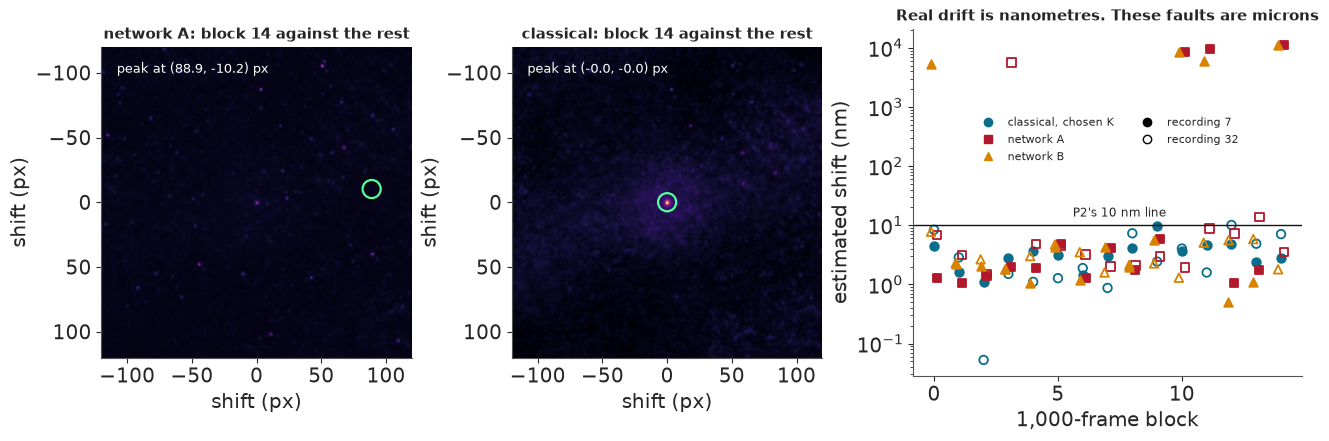

In [19]:
def shift_um(rec, tail, method):
    return pack[f"{rec}_drift{tail}_{method}"] * PIXEL_NM / 1000


print(f"{'':28}{'largest shift':>15}{'blocks over 1 um':>18}{'largest axis range':>20}")
for rec in RECS:
    for tail in ("", "_line"):
        for method in ("chosen", "a", "b"):
            d = shift_um(rec, tail, method)
            print(f"{RECS[rec]:13}{tail[1:] or 'per block':10}{method:6}{np.abs(d).max() * 1000:>12,.0f} nm"
                  f"{(np.abs(d).max(1) > 1).sum():>15} of 15{np.ptp(d, axis=0).max() * 1000:>15,.0f} nm")


def smooth(h):
    return ndi.gaussian_filter(h.astype(float), 1.0)


def cross(a, c):
    return np.fft.fftshift(np.fft.irfft2(np.fft.rfft2(a - a.mean()) * np.conj(np.fft.rfft2(c - c.mean())), s=a.shape))


def peak_shift(cc, px_per_bin=0.25):
    """Sub-bin peak of a centred cross-correlation, by a quadratic through the peak on each axis."""
    y, x = np.unravel_index(cc.argmax(), cc.shape)

    def vertex(a, c, e):
        return 0.5 * (a - e) / (a - 2 * c + e)

    dy, dx = vertex(cc[y - 1, x], cc[y, x], cc[y + 1, x]), vertex(cc[y, x - 1], cc[y, x], cc[y, x + 1])
    return np.array([x + dx - cc.shape[1] // 2, y + dy - cc.shape[0] // 2]) * px_per_bin


block = int(pack["drift_demo_block"])
maps = {name: cross(smooth(pack[f"drift_demo_{name}_block"]), smooth(pack[f"drift_demo_{name}_rest"])) for name in ("a", "chosen")}
found = {name: -peak_shift(cc) for name, cc in maps.items()}
print(f"\nLive, block {block} of recording 7, from the stored renders:")
print(f"  network A: shift ({found['a'][0]:.1f}, {found['a'][1]:.1f}) px = {np.hypot(*found['a']) * PIXEL_NM / 1000:.1f} um. Stored: {pack['r7_drift_a'][block].round(1)}")
print(f"  classical: shift ({found['chosen'][0]:.2f}, {found['chosen'][1]:.2f}) px = {np.hypot(*found['chosen']) * PIXEL_NM:.0f} nm; "
      f"stored leave-block-out estimate of the same block {np.hypot(*p2['drift_leave_block_out_nm'][block]):.0f} nm")
assert np.allclose(found["a"], pack["r7_drift_a"][block], atol=1e-2), "the live estimate reproduces the stored fault"
pile_block = np.unravel_index(pack["drift_demo_a_block"].argmax(), (800, 800))
pile_rest = np.unravel_index(pack["drift_demo_a_rest"].argmax(), (800, 800))
to_px = lambda ij: np.array(ij[::-1]) * 0.25 - 0.375
print(f"  Fullest bin in the block: {pack['drift_demo_a_block'].max():,} rows at (x, y) {to_px(pile_block)}; "
      f"in the rest: {pack['drift_demo_a_rest'].max():,} rows at {to_px(pile_rest)}")
print(f"  Their separation: {to_px(pile_rest) - to_px(pile_block)} px. Typical occupied bin: "
      f"{int(np.median(pack['drift_demo_a_block'][pack['drift_demo_a_block'] > 0]))} row.")
print(f"  Full movie, fullest 0.25 px bin: A {pack['r7_render_a'].max():,}, B {pack['r7_render_b'].max():,}, classical {pack['r7_render_chosen'].max():,}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), width_ratios=[1, 1, 1.25], layout="constrained")
for ax, name, title in ((axes[0], "a", "network A"), (axes[1], "chosen", "classical")):
    cc = maps[name]
    ax.imshow(cc / cc.max(), cmap="magma", extent=(-200, 200, 200, -200), interpolation="nearest", vmin=-0.05, vmax=1)
    ax.set(xlim=(-120, 120), ylim=(120, -120), xlabel="shift (px)", ylabel="shift (px)")
    ax.set_title(f"{title}: block {block} against the rest", fontsize=10.5)
    peak = peak_shift(cc)
    ax.add_patch(plt.Circle(peak, 7, fill=False, ec="#55ff99", lw=1.6))
    ax.text(-108, -100, f"peak at ({peak[0] + 0:.1f}, {peak[1] + 0:.1f}) px", color="w", fontsize=9)
ax = axes[2]
blocks = np.arange(15)
for method, marker in (("chosen", "o"), ("a", "s"), ("b", "^")):
    for rec, fill in (("r7", True), ("r32", False)):
        d = np.hypot(*shift_um(rec, "", method).T) * 1000
        ax.scatter(blocks + {"chosen": 0, "a": 0.12, "b": -0.12}[method], d, s=38, marker=marker,
                   facecolor=COLOUR[method] if fill else "none", edgecolor=COLOUR[method], lw=1.3)
ax.axhline(10, color=LINE_COL, lw=1)
ax.text(5.6, 14, "P2's 10 nm line", fontsize=8.5)
ax.set_yscale("log")
ax.set(xlabel="1,000-frame block", ylabel="estimated shift (nm)")
ax.set_title("Real drift is nanometres. These faults are microns", fontsize=10.5)
ax.legend(handles=[Line2D([], [], marker=m, ls="", color=COLOUR[k], label=NAME[k]) for k, m in (("chosen", "o"), ("a", "s"), ("b", "^"))]
          + [Line2D([], [], marker="o", ls="", color="k", label="recording 7"),
             Line2D([], [], marker="o", ls="", mfc="none", color="k", label="recording 32")], fontsize=8, loc="center", bbox_to_anchor=(0.5, 0.68), ncols=2);

**What broke.** Classical drift stays within 5-18 nm. On network rows the same method returned shifts of
up to 11.6 µm in 1-4 of the 15 blocks, in all but one of the network runs. A few fixed spots pile up
thousands of network rows in a single 0.25 px bin (3,888 for A and 4,955 for B), where a typical bin holds
one and classical piles reach only 424. A cross-correlation peak is dominated by its strongest sources,
so it lines up two *different* piles and calls the difference drift. The live result above reproduces
it: in block 14 of recording 7 the peak falls at the separation of the two fullest bins, 11.4 µm, while
the classical rows give 3 nm.

**What the piles are.** The fullest spots are long-lived bright objects that switch on and off for
thousands of frames; recording 7's reads about 2,500 ADU against 1,150 nearby. The fitter's 201-frame
rolling background removes them, but a network that sees 3 frames cannot know an object has been there for
a minute. In the simulated movie, whose backgrounds come from recording 7, the networks' false rows sit
near the fullest real piles 13-18 times as often as true rows do.

The networks' frame counts used those shifts: B gave 86 clusters at 2,000 frames of recording 7, against
413 under the other calibration, a gap that looks like a calibration effect but is not. The repair
applies the classical drift of the same recording to the network rows, since drift belongs to the sample,
not the localiser. Section 12 shows both versions. A pipeline
step validated on one kind of input is unvalidated on another: classical and network rows have the same
columns, and not the same distribution.

## 11 · The third failure: a flattering split

This failure was predicted, and it has nothing to do with networks. FRC (Nieuwenhuizen et al. 2013) splits
the localisations in two, renders each half, and asks at what scale the two renders stop agreeing. A
random split puts half of each blink in each half, and here about 40% of rows link into the next frame, so
the halves share molecules and agree at scales that have nothing to do with resolution. The fix merges
linked rows into events and splits by time blocks of 50 frames.

FRC at 15,000 frames, nm           random    block     gap
recording 7, classical               31.4     35.3     3.9
recording 7, network A, post-hoc     29.1     32.0     2.9
recording 7, network B, post-hoc     22.4     30.4     8.0
recording 32, classical              31.3     41.2    10.0
recording 32, network A, post-hoc     29.5     36.0     6.5
recording 32, network B, post-hoc     29.3     41.1    11.8


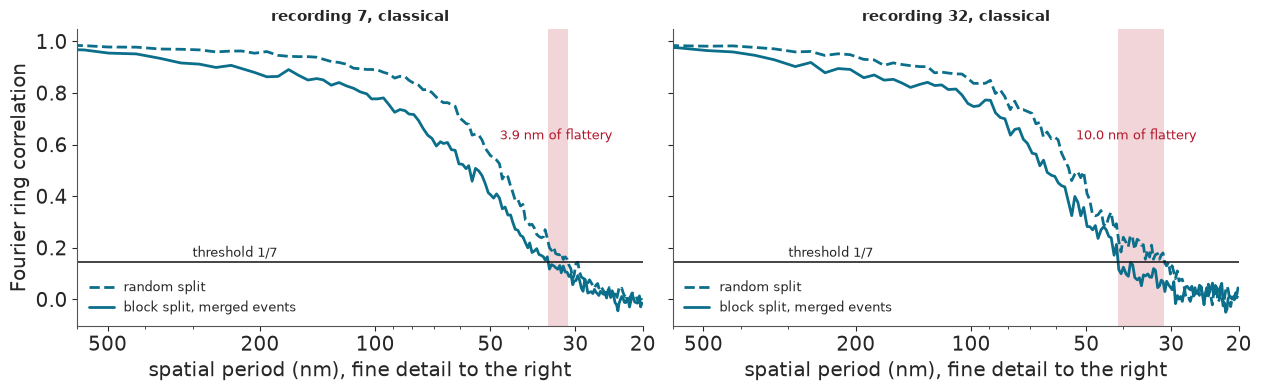

In [20]:
split, split_post = store.load_json("frc_split"), store.load_json("frc_split_cdrift")
print(f"{'FRC at 15,000 frames, nm':32}{'random':>9}{'block':>9}{'gap':>8}")
for rec in RECS:
    r = split[rec]["chosen"]
    print(f"{RECS[rec] + ', classical':32}{r['random_split_nm']:>9.1f}{r['block_split_nm']:>9.1f}{r['gap_nm']:>8.1f}")
    for net in ("a", "b"):
        r = split_post[rec][net]
        print(f"{RECS[rec] + ', ' + NAME[net] + ', post-hoc':32}{r['random_split_nm']:>9.1f}{r['block_split_nm']:>9.1f}{r['gap_nm']:>8.1f}")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True, layout="constrained")
for ax, rec in zip(axes, RECS):
    for kind, ls, label in (("random", "--", "random split"), ("block", "-", "block split, merged events")):
        curve = pack[f"{rec}_frc_{kind}_chosen"]
        ax.plot(curve[:, 0], curve[:, 1], color=CLASSICAL, ls=ls, lw=2, label=label)
    ax.axhline(1 / 7, color=LINE_COL, lw=1.1)
    ax.text(300, 0.165, "threshold 1/7", fontsize=9)
    low, high = split[rec]["chosen"]["random_split_nm"], split[rec]["chosen"]["block_split_nm"]
    ax.axvspan(low, high, color=NET_A, alpha=0.18, lw=0)
    ax.annotate(f"{high - low:.1f} nm of flattery", (high, 0.55), xytext=(high + 12, 0.62), fontsize=9.5, color=NET_A)
    ax.set_xscale("log")
    ax.set(xlim=(600, 20), xlabel="spatial period (nm), fine detail to the right")
    ax.set_xticks([20, 30, 50, 100, 200, 500], ["20", "30", "50", "100", "200", "500"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(f"{RECS[rec]}, classical", fontsize=11)
    ax.legend(loc="lower left", fontsize=9)
axes[0].set_ylabel("Fourier ring correlation");

The split alone is worth up to 10 nm on classical rows (31.3 against 41.2 nm on recording 32) and up to 12
nm on network rows. Even the block split is optimistic, since a molecule that returns after a long dark
period can land in both halves. Always name the split when you quote FRC.

## 12 · The frames decision, all of it

Now the third question: would the network change the answer? The table has the network runs with the
original drift and with the repaired drift, each under both calibrations.

   method         status  per block  (rec 7, rec 32)  line (rec 7, rec 32) 
Classical      reference      10500  (10,500, 7,500) 12000  (12,000, 5,000)
Network A gated, unsound      10500  (10,500, 7,500) 10500  (10,500, 6,000)
Network B gated, unsound      12000  (12,000, 6,000) 10500  (10,500, 6,000)
Network A post-hoc drift      12000 (10,500, 12,000) 15000 (15,000, 10,500)
Network B post-hoc drift      10500  (10,500, 6,000) 13500  (13,500, 7,500)

Classical range quoted: 10,500-12,000, or 20%-30% fewer frames
Spread of N for both over classical and post-hoc A and B, per block: 1,500
Spread of N for both over classical and post-hoc A and B, one line: 3,000
Moved by the line, post-hoc A: 3,000; post-hoc B: 3,000; classical: 1,500
Rows per frame in the first block of recording 7: B per block 55, B under the line 123; A 127 and 161; classical 81 and 87


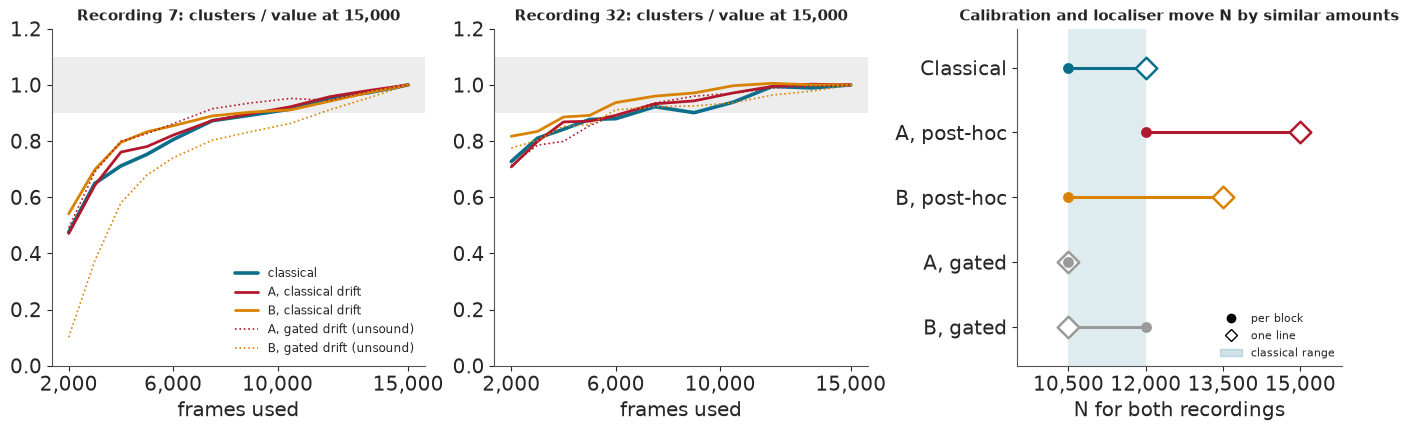

In [21]:
stored = summary["decision"]
post = store.load_json("decision_posthoc_cdrift")["decision"]
table = []
for label, key, source, status in (("Classical", "classical", stored, "reference"), ("Network A", "a", stored, "gated, unsound"),
                                   ("Network B", "b", stored, "gated, unsound"), ("Network A", "a", post, "post-hoc drift"),
                                   ("Network B", "b", post, "post-hoc drift")):
    a, b = source[key], source[f"{key}_line"]
    table.append({"method": label, "status": status, "per block": a["N_both"], "(rec 7, rec 32)": f"({a['r7']:,}, {a['r32']:,})",
                  "line": b["N_both"], "(rec 7, rec 32) ": f"({b['r7']:,}, {b['r32']:,})"})
print(pd.DataFrame(table).to_string(index=False))
print(f"\nClassical range quoted: {stored['classical']['N_both']:,}-{stored['classical_line']['N_both']:,}, or "
      f"{1 - stored['classical_line']['N_both'] / FRAMES:.0%}-{1 - stored['classical']['N_both'] / FRAMES:.0%} fewer frames")
for title, tail in (("per block", ""), ("one line", "_line")):
    values = [(stored if key == "classical" else post)[key + tail]["N_both"] for key in ("classical", "a", "b")]
    print(f"Spread of N for both over classical and post-hoc A and B, {title}: {max(values) - min(values):,}")
print(f"Moved by the line, post-hoc A: {post['a_line']['N_both'] - post['a']['N_both']:,}; post-hoc B: "
      f"{post['b_line']['N_both'] - post['b']['N_both']:,}; classical: {stored['classical_line']['N_both'] - stored['classical']['N_both']:,}")
print(f"Rows per frame in the first block of recording 7: B per block {pack['r7_rows_per_block_b'][0] / 500:.0f}, B under the line "
      f"{pack['r7_rows_per_block_b_line'][0] / 500:.0f}; A {pack['r7_rows_per_block_a'][0] / 500:.0f} and {pack['r7_rows_per_block_a_line'][0] / 500:.0f}; "
      f"classical {pack['r7_rows_per_block_chosen'][0] / 500:.0f} and {pack['r7_rows_per_block_chosen_line'][0] / 500:.0f}")

fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.2), width_ratios=[1.15, 1.15, 1], layout="constrained")
for ax, rec in zip(axes, RECS):
    runs = (("classical", CLASSICAL, "-", 2.6, "classical"), ("a_cdrift", NET_A, "-", 2, "A, classical drift"),
            ("b_cdrift", NET_B, "-", 2, "B, classical drift"), ("a", NET_A, ":", 1.2, "A, gated drift (unsound)"),
            ("b", NET_B, ":", 1.2, "B, gated drift (unsound)"))
    for key, colour, ls, lw, label in runs:
        y = np.array([decisions[key][rec]["points"][str(N)]["count"] for N in GRID])
        ax.plot(GRID, y / y[-1], color=colour, ls=ls, lw=lw, label=label)
    ax.axhspan(0.9, 1.1, color="#555555", alpha=0.1, lw=0)
    ax.set(xlabel="frames used", ylim=(0, 1.2))
    ax.set_xticks([2000, 6000, 10000, 15000], ["2,000", "6,000", "10,000", "15,000"])
    ax.set_title(f"{RECS[rec].capitalize()}: clusters / value at 15,000", fontsize=10.5)
axes[0].legend(fontsize=8.5, loc="lower right")
ax = axes[2]
rows = [("Classical", stored["classical"], stored["classical_line"], CLASSICAL, True), ("A, post-hoc", post["a"], post["a_line"], NET_A, True),
        ("B, post-hoc", post["b"], post["b_line"], NET_B, True), ("A, gated", stored["a"], stored["a_line"], MUTED, False),
        ("B, gated", stored["b"], stored["b_line"], MUTED, False)]
ax.axvspan(10500, 12000, color=CLASSICAL, alpha=0.13, lw=0)
for i, (label, block_row, line_row, colour, sound) in enumerate(rows[::-1]):
    ax.plot([block_row["N_both"], line_row["N_both"]], [i, i], color=colour, lw=2.2, zorder=2)
    ax.scatter(line_row["N_both"], i, s=120, marker="D", facecolor="w", edgecolor=colour, lw=1.8, zorder=3)
    ax.scatter(block_row["N_both"], i, s=46, color=colour, zorder=4)
ax.set_yticks(range(5), [r[0] for r in rows[::-1]])
ax.set(xlim=(9500, 15800), ylim=(-0.6, 4.6), xlabel="N for both recordings")
ax.set_xticks([10500, 12000, 13500, 15000], ["10,500", "12,000", "13,500", "15,000"])
ax.set_title("Calibration and localiser move N by similar amounts", fontsize=10.5)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="k", label="per block"),
                   Line2D([], [], marker="D", ls="", mfc="w", color="k", label="one line"),
                   Patch(color=CLASSICAL, alpha=0.2, label="classical range")], fontsize=8, loc="lower right", bbox_to_anchor=(1.01, -0.01));

**With the original drift, the network changes the decision, and that is not a finding**: B's 12,000 rests
on the drift fault. After the repair, per block, B agrees with classical at 10,500 and A sits one grid
step higher at 12,000, inside the classical range. Under the line calibration the repaired networks read
15,000 (A) and 13,500 (B), above it. These come from networks that failed their checks, after a repair
chosen once the fault was seen, so the number we stand behind is the classical one.

**Calibration and localiser matter about equally.** After the repair the line calibration adds 3,000
frames to both networks and 1,500 to classical, and the choice of localiser spreads N by 1,500-3,000
frames. The unsettled calibration of section 2 is worth about as much to this answer as the network is,
and the bootstrap of section 3 says neither shift stands clear of sampling noise.

Nor do the curves support a claim that the network sees *more*. Look at the same 3 µm square through all
three.

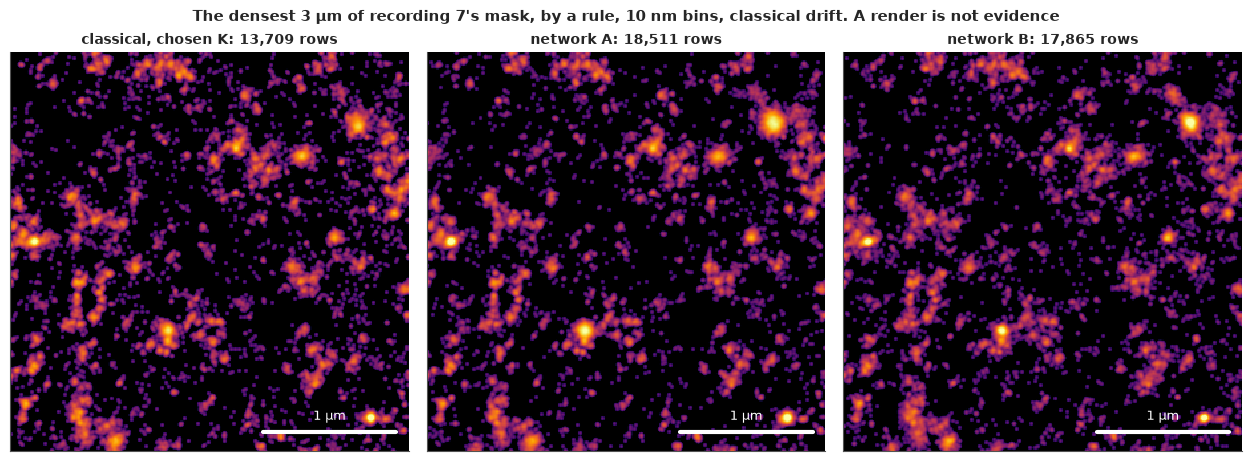

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.5), layout="constrained")
for ax, m in zip(axes, ("chosen", "a", "b")):
    image = ndi.gaussian_filter(pack[f"zoom_{m}"].astype(float), 1.0)
    ax.imshow(np.ma.masked_less(image, 0.02), cmap=DARK, norm=LogNorm(0.02, max(image.max() * 0.4, 1)), interpolation="nearest")
    ax.plot([190, 290], [285, 285], color="w", lw=3)
    ax.text(240, 276, "1 µm", color="w", ha="center", fontsize=9)
    ax.set_title(f"{NAME[m]}: {int(pack[f'zoom_{m}'].sum()):,} rows", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor("black")
fig.suptitle("The densest 3 µm of recording 7's mask, by a rule, 10 nm bins, classical drift. A render is not evidence", fontsize=11);

They look alike, and the networks' pictures hold more rows and look a little crisper. But these are the
rows that failed section 7: a crisp render cannot tell you whether its error bars are honest.

### The whole recording in one movie

Here is the decision as a process, on classical rows. Left: a raw frame from a 40 px window. Middle: the
events found so far. Right: the whole mask's cluster count against the 10% band. Watch the middle panel
keep filling in after the count has entered the band. That is what a 10% allowance gives up.

In [23]:
ids = pack["animation_frames"]
raw = pack["animation_raw"]
events_xy, events_t = pack["animation_xy"], pack["animation_t"]
curve = np.array([decisions["classical"]["r7"]["points"][str(N)]["count"] for N in GRID])
counts = np.interp(ids, GRID, curve)
edges = np.arange(0, 40.01, 0.125)


def density_at(n):
    keep = events_t < n
    return np.histogram2d(events_xy[keep, 1], events_xy[keep, 0], bins=[edges, edges])[0]


plt.rcParams["animation.embed_limit"] = 12
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5), width_ratios=[1, 1, 1.25], layout="constrained")
raw_image = axes[0].imshow(raw[0], cmap="gray", vmin=np.percentile(raw, 1), vmax=np.percentile(raw, 99.8), interpolation="nearest")
cloud = axes[1].imshow(np.ma.masked_equal(density_at(int(ids[0])), 0), cmap=DARK, norm=LogNorm(1, 12), interpolation="nearest")
axes[0].set_title("raw frame", fontsize=10)
axes[1].set_title("events so far", fontsize=10)
axes[1].set_facecolor("black")
for ax in axes[:2]:
    ax.set_xticks([])
    ax.set_yticks([])
ax = axes[2]
ax.plot(GRID, curve, color=CLASSICAL, lw=1.6)
ax.axhspan(curve[-1] * 0.9, curve[-1] * 1.1, color=CLASSICAL, alpha=0.12, lw=0)
ax.axvline(10500, color=LINE_COL, lw=1, ls=":")
ax.text(10600, 40, "N*", fontsize=9)
dot, = ax.plot([], [], "o", ms=9, color=NET_A)
label = ax.set_title("", fontsize=10)
ax.set(xlim=(0, 15500), ylim=(0, 900), xlabel="frames", ylabel="clusters, whole mask")


def update(i):
    raw_image.set_data(raw[i])
    cloud.set_data(np.ma.masked_equal(density_at(int(ids[i])), 0))
    dot.set_data([ids[i]], [counts[i]])
    label.set_text(f"frame {int(ids[i]):,} of 15,000, {ids[i] * CYCLE_MS / 1000:.0f} s")
    return raw_image, cloud, dot, label


movie = animation.FuncAnimation(fig, update, frames=len(ids), interval=220, blit=False)
html = movie.to_jshtml(fps=5, default_mode="once", embed_frames=True)
plt.close(fig)
print(f"{len(ids)} frames, {len(html) / 1e6:.1f} MB of HTML")
HTML(html)

36 frames, 2.2 MB of HTML


## 13 · What to tell the core

### The certificate

A trained network is an instrument, and it should ship with a calibration certificate, the way a balance
does: what it was trained on, where it was tested, how it did there and on real data, and what it has
never seen. Here is network B's, generated from the stored file.

In [24]:
real = certificate["real"]
near = {(n, w): near_nominal(n, w)[0] for n in ("a", "b") for w in ("gauss", "empirical")}
ood = store.load_json("ood532")
page = pd.DataFrame([
    ("Instrument", certificate["instrument"]),
    ("Trained on, A", certificate["trained_on"]["a"]),
    ("Trained on, B", certificate["trained_on"]["b"] + ". The stacked PSF carries a pedestal and site structure: 5-6% of its light lies beyond 3 px after a control, not the stored 25%, post-hoc"),
    ("Range tested", f"density 0.02-1.5 per µm², of which the training prior covers {certificate['ranges']['density_per_um2'][0]}-{certificate['ranges']['density_per_um2'][1]}, 500-4,000 photons, background 110 photons in the coverage grid"),
    ("Coverage on simulation", f"Near-nominal in 16 cells: A own world {near[('a', 'gauss')]}, B in A's world {near[('b', 'gauss')]}; empirical world A {near[('a', 'empirical')]}, B {near[('b', 'empirical')]}"),
    ("Real data: error bars", f"Paired z, recording 32: A {real['paired']['r32_a']['z']:.2f}, B {real['paired']['r32_b']['z']:.2f}, classical {real['paired']['r32_a']['classical_z']:.2f}. **Failure line 1.25: fail**"),
    ("Real data: false detections", f"Halo, recording 32: A {real['halo']['r32']['a']:.2f}, B {real['halo']['r32']['b']:.2f}. **Line 2: fail**"),
    ("Real data: the fitter it replaces", f"NUTS over Laplace sd {real['nuts_median_sd_ratio']['all']:.2f} on all spots, **line 1.25: fail**. Our chains started at the patch corner: rerun post-hoc from the spot, {cold['median_sd_ratio']['all']:.2f}-{warm['median_sd_ratio']['all']:.2f}, K = 1 {cold['median_sd_ratio']['K1']:.2f}, K = 2 {warm['median_sd_ratio']['K2']:.2f}-{cold['median_sd_ratio']['K2']:.2f}, unresolved (sections 7-8)"),
    ("Grid pattern", f"Mean p by 8 px cell, max over min, recording 32: A {certificate['p6_grid_ratio_all_frames']['a_r32']:.2f}, B {certificate['p6_grid_ratio_all_frames']['b_r32']:.2f}. **Line 1.25: fail** as written, cause on full frames unconfirmed"),
    ("Never tested", "; ".join(certificate["never_tested"])),
    ("Output with no evidence", f"Four 532 nm frames, a different dye, gave A {ood['a']['found_per_frame']:.1f} and B {ood['b']['found_per_frame']:.1f} detections per frame with sds near {ood['b']['median_sd_nm']:.0f} nm. The certificate says: {ood['certificate']}"),
    ("Do not use for", "Position error bars at face value on these recordings; any count without the halo check; any other sample without repeating every check"),
], columns=["Item", "Finding"])
display(markdown_table(page))

| Item | Finding |
|---|---|
| Instrument | Network B (and A) DECODE-style U-Net, base 32, tested only as listed |
| Trained on, A | E58's forward model, Gaussian PSF, flat background, independent frames |
| Trained on, B | empirical radial PSF, defocus, real block-median maps and persistence, recording 7 only. The stacked PSF carries a pedestal and site structure: 5-6% of its light lies beyond 3 px after a control, not the stored 25%, post-hoc |
| Range tested | density 0.02-1.5 per µm², of which the training prior covers 0.02-0.8, 500-4,000 photons, background 110 photons in the coverage grid |
| Coverage on simulation | Near-nominal in 16 cells: A own world 13, B in A's world 8; empirical world A 8, B 10 |
| Real data: error bars | Paired z, recording 32: A 1.40, B 1.63, classical 1.63. **Failure line 1.25: fail** |
| Real data: false detections | Halo, recording 32: A 5.39, B 2.69. **Line 2: fail** |
| Real data: the fitter it replaces | NUTS over Laplace sd 1.54 on all spots, **line 1.25: fail**. Our chains started at the patch corner: rerun post-hoc from the spot, 1.11-1.14, K = 1 1.02, K = 2 1.85-1.91, unresolved (sections 7-8) |
| Grid pattern | Mean p by 8 px cell, max over min, recording 32: A 1.72, B 2.01. **Line 1.25: fail** as written, cause on full frames unconfirmed |
| Never tested | 532 channel; any preparation but these two recordings; density above 1.5 or below 0.02 per um^2 on simulation; ground truth on real frames |
| Output with no evidence | Four 532 nm frames, a different dye, gave A 123.5 and B 209.5 detections per frame with sds near 30 nm. The certificate says: never tested here |
| Do not use for | Position error bars at face value on these recordings; any count without the halo check; any other sample without repeating every check |

Note the 532 nm row. Frames from the other channel, a dye the networks never saw, gave 124-210 detections
per frame with sds near 30 nm. A network given unfamiliar data produces a tidy table of confident
detections, and nothing in its output says anything is wrong. Only the certificate does.

### The answer for the core

For these two recordings, 10,500-12,000 frames would have given the same answer as 15,000. If the core
cuts at all, 12,000 is the working number, saving about 26 minutes and 11 GB per channel. Pilot the next
sample first: recording 7 alone sets the number, and recording 32 settles 3,000-7,000 frames earlier, a
gap the bootstrap cannot resolve.

Do not replace the fitter on this evidence. The network runs fast, looks crisp and passed simulation, and
it failed the paired test and the halo on a recording it had not seen. This is one design, one training
budget and one pair of simulators, on data of low density; it says nothing about networks in general, and
a better simulator may well do better. Before trusting any network, ask for the four checks of section 7
and a certificate. All of them run without ground truth, and none of them tests accuracy: a bias shared by
both frames of a pair would pass them all.

The fitter's error bars are too small as well. Add a floor of a few nanometres before scaling them, and
treat the $K = 2$ sds with caution. Finally, settle the calibration: it moved the answer as much as the
localiser did, though neither shift stands clear of sampling noise, and these recordings have no dark
frames, so recording some is the obvious next step.

The last cell checks the numbers this notebook quotes against the stored files, and reports the replay's
run time.

In [25]:
near_value = lambda value, want, tol=0.006: abs(value - want) <= tol
assert summary["outcome"] == "B" and summary["fails_a"]["paired_z"] and summary["fails_b"]["paired_z"]
assert stored["classical"]["N_both"] == 10500 and stored["classical_line"]["N_both"] == 12000
assert (stored["classical"]["r7"], stored["classical"]["r32"], stored["classical_line"]["r7"], stored["classical_line"]["r32"]) == (10500, 7500, 12000, 5000)
assert stored["a"]["N_both"] == 10500 and stored["b"]["N_both"] == 12000 and post["a"]["N_both"] == 12000 and post["b"]["N_both"] == 10500
assert post["a_line"]["N_both"] == 15000 and post["b_line"]["N_both"] == 13500
assert near_value(v["r32_a"]["z"], 1.40) and near_value(v["r32_b"]["z"], 1.63) and near_value(v["r32_a"]["classical_z"], 1.63)
assert near_value(v["r32_a"]["k1_z"], 1.49) and near_value(v["r32_line_a"]["z"], 1.39) and near_value(v["r32_line_b"]["z"], 1.61)
assert all(v[f"{k}_{n}"]["absolute"] == "failure" for k in ("r32", "r7", "r32_line", "r7_line") for n in ("a", "b"))
assert all(v[f"{k}_{n}"]["relative"] == "no worse than classical" for k in ("r32", "r7") for n in ("a", "b"))
assert near_value(halo["r32"]["b"]["ratio"], 2.69) and near_value(halo["r7"]["b"]["ratio"], 1.95)
assert near_value(summary["p5_at_final"]["a"]["tol2.0"]["recall"], 0.994) and near_value(summary["p5_at_final"]["a"]["rmse_over_crlb"], 1.16)
assert near_value(audit["median_sd_ratio"]["all"], 1.54) and (audit["over_1_01"]["K1"] + audit["over_1_01"]["K2"]) / 200 == 0.435
assert decisions["classical"]["r7"]["blobs"] == 367071 and decisions["classical"]["r32"]["blobs"] == 245335
assert p2["rows_filtered"] == 340711
assert near_value(decisions["classical"]["r7"]["points"]["2000"]["frc_nm"], 32.8, 0.05) and near_value(decisions["classical"]["r7"]["points"]["15000"]["frc_nm"], 35.3, 0.05)
assert 1.08 < decisions["classical"]["r7"]["points"]["15000"]["count"] / decisions["classical"]["r7"]["points"]["10500"]["count"] < 1.10
assert near_value(dense, 0.43, 0.01) and near_value(ratio, 44, 0.5)
assert decisions["b"]["r7"]["points"]["2000"]["count"] == 86 and decisions["b_line"]["r7"]["points"]["2000"]["count"] == 413
band = decisions["classical"]["r7"]["bands"]["15000"]
assert (round(band["count_q"][0]), round(band["count_q"][1]), round(band["frc_q"][0]), round(band["frc_q"][1])) == (889, 989, 45, 56)
assert round(pack["r7_mask"].mean(), 3) == 0.128 and round(pack["r32_mask"].mean(), 3) == 0.072
assert pack["r7_render_chosen"].max() == 424 and min(split_post[r][n]["gap_nm"] for r in RECS for n in ("a", "b")) > 2.8
assert max(split["r32"]["chosen"]["gap_nm"], split["r7"]["chosen"]["gap_nm"]) < 10.0 and split_post["r32"]["b"]["gap_nm"] < 12
assert all(pack[f"{r}_blobs_per_block"][-1] < pack[f"{r}_blobs_per_block"][0] / 2 for r in RECS)
assert np.argmax(halo["r32"]["a"]["density"]) == 10 and 500 <= halo["r32"]["a"]["edges_nm"][10] < 550
assert np.abs(shift_um("r7", "_line", "b")).max() < 12 and max(np.abs(shift_um(r, t, "chosen")).max() for r in RECS for t in ("", "_line")) < 0.02
sim_rows, real_rows, boot = posthoc["sim"], posthoc["real"], frames_boot["calibrations"]
assert near_value(paired["rows"]["r32"]["K1"]["gap3_R1.5"]["matched_chosen"]["z_sd"], 1.427, 0.001) and near_value(paired["rows"]["r32"]["b"]["gap3_R1.5"]["matched_K1"]["z_sd"], 1.686, 0.001)
assert near_value(paired["rows"]["r7"]["a"]["gap3_R1.5"]["unweighted"]["z_sd"], 1.235, 0.001) and paired["rows"]["r7"]["a"]["gap3_R1.5"]["unweighted"]["z_sd_hi"] < 1.25
assert (near_value(sim_rows["a"]["precision"], 0.505, 0.001), near_value(sim_rows["b"]["precision"], 0.865, 0.001), sim_rows["a"]["pairs_neither"]) == (True, True, 34028)
assert all(1.06 <= sim_rows[m]["z_both_true"] <= 1.13 for m in ("a", "b", "chosen", "K1")) and near_value(sim["b"]["gap1_R1.5"]["unweighted"]["z_sd"], 0.59, 0.01)
assert real_rows["r32"]["common"]["pairs"] == 4337 and near_value(real_rows["r32"]["common"]["z"]["b"], 1.76, 0.01) and near_value(real_rows["r32"]["common"]["z"]["a"], 1.44, 0.01)
assert all(3.8 <= real_rows[r]["floor"][m]["floor_nm"] / np.sqrt(2) <= 6.0 for r in RECS for m in ("a", "b", "chosen", "K1"))
assert all(real_rows["r32"]["sd_tertiles"][m][0] > real_rows["r32"]["sd_tertiles"][m][2] for m in ("a", "b", "K1", "chosen"))
assert boot["per_block"]["both_95"] == [7500, 13500] == boot["line"]["both_95"] and min(boot["per_block"]["r32"]["stars"]) == 2000 and max(boot["per_block"]["r32"]["stars"]) == 12000
assert sum(v["margin"] < 0 for k, v in frames_boot["band_seeds"].items() if k != "88") == 1 and near_value(margins[88], 11, 0.1)
assert 0.05 <= psf_control["controls"]["after_100"]["share_difference"] <= 0.06 and near_value(psf_control["controls"]["random_sites"]["integral_control"], 0.23, 0.01)
assert (cold["over_1_01"]["K1"], warm["over_1_01"]["K1"], cold["K1_fit"]["within_half_px"]) == (0, 0, 99) and 0.8 <= cold["median_sd_ratio"]["all"] <= 1.25 and 0.8 <= warm["median_sd_ratio"]["all"] <= 1.25
assert near_value(stuck_chains["best_chain_sd_ratio"]["all"], 1.07, 0.01) and stuck_chains["K1_fit"]["on_best_chain"] == 25
assert near_value(real_rows["r7"]["persist_gap1_share_of_rows"], 0.42, 0.005) and near_value(real_rows["r32"]["persist_gap1_share_of_rows"], 0.38, 0.005)
assert near_value(min(r["precision"] for r in emp_a), 0.42, 0.01) and near_value(p8_slow / p8_fast, 3.4, 0.05) and near_value(p4_gpu["steps_per_s"] / p4_cpu["steps_per_s"], 44, 0.5)
assert decisions["b_cdrift"]["r7"]["points"]["2000"]["count"] == 402 and decisions["b_line_cdrift"]["r7"]["points"]["2000"]["count"] == 419
assert abs(as_stored["live_r_hat"] - 3.012) < 0.01 and all(abs(v) < 2.5 for v in np.r_[first["x"].values[:, 0, 0], first["y"].values[:, 0, 0]])
assert live[0]["live_r_hat"] <= 1.01 and live[1]["live_r_hat"] <= 1.01, "with the start on the spot both K = 1 spots converge, whatever the compile cache"
print("The stored numbers the argument rests on: checked. Section 8's K = 2 row is live and is not asserted, because it depends on the compile cache.")
print(f"Replay finished in {(time.perf_counter() - started) / 60:.1f} min on {CORES} cores.")

The stored numbers the argument rests on: checked. Section 8's K = 2 row is live and is not asserted, because it depends on the compile cache.
Replay finished in 1.0 min on 2 cores.


## Summary

- **Frames: 10,500-12,000, 20-30% fewer than 15,000.** The stability rule gives 10,500 under
  per-block calibration and 12,000 under the more plausible one-line calibration, found afterwards; a
  block bootstrap gives 7,500-13,500. 10,500 holds narrowly, so 12,000 is safer. The cluster count
  decided, not FRC, and it tracks the number of events rather than a settled structure (section 3).
- **The two recordings differ by 3,000-7,000 frames**, a gap sampling noise cannot resolve (recording 32
  alone runs 2,000-12,000 across the bootstrap), and recording 7 sets the answer for both. With two
  recordings of unknown relation, no rule for a lab follows.
- **The camera calibration is unsettled**: per-block fits move by over 200 ADU and 30%, probably partly a
  fitting artefact, and the two calibrations give N 1,500-3,000 frames apart, a shift the block bootstrap
  cannot tell from sampling noise (sections 2, 3, 12).
- **A simulation pass is not a pass.** Network A reached recall 0.994 at 1.16 times the CRLB on its own
  simulator, and on real frames both networks failed the paired-frame test ($z$ 1.40 and 1.63 against
  1.25) and the halo (5.4 and 2.7 against 2). B's fix halved the halo but made $z$ worse (sections 6-7).
- **The classical error bars are too small too** ($z$ 1.63), partly from a floor of about 4-6 nm per frame
  common to every method; the rest is unexplained. On common pairs B is worse than classical and A only
  matches single-emitter fits, so neither gives a reason to switch (section 7).
- **The NUTS audit failed mostly through a bad start**: nutpie's `with_data` kept the start at the patch
  corner. Started on the spot, the ratio is 1.11-1.14 and Laplace looks sound at $K = 1$ on recording 7,
  with 8-9 divergences left; $K = 2$ is open (sections 7-8).
- **Cross-correlation drift breaks on network rows**, turning piles of long-lived bright objects into
  micron shifts. Repaired, the networks give 10,500-15,000 frames, not a change we can trust (sections 10,
  12).
- **A random split flatters FRC** by up to 10-12 nm (section 11).
- **There was little for a network to find**: overlaps are under 10% here, against 43% in E58's dense
  simulation.

## Try it yourself

The first two run in seconds on the stored summary. The third recompiles the models, which took 17-44 s
here.

1. **Move the allowance, and the rule.** `n_both` takes the 10%. Replace "every larger N" with "this N
   only" in `n_star`, and see which recording changes. What would an honest report say if the answer moved
   by two grid steps?
2. **Make drift robust.** Clip the renders passed to `cross` at a low count, say 3 rows per bin, so that
   no pile can dominate, and rerun block 14 for network A and for classical. Does the classical answer
   survive?
3. **Move the start, then free $K = 2$.** In section 8, run the $K = 2$ spots with `centred=True` and see
   how far the corner start takes them. Then keep the non-centred form and tighten the position prior from
   2.0 to 0.5 px. Do the chains now agree? Is that a better model of the pixels, or only a better-behaved
   sampler?